# VoltAhead — XGBoost Classifier (Steps 3–5)
Develop, evaluate and optimize an XGBoost model predicting EV charging **availability 30/40/60 min ahead** (`1 = Available`, `0 = Unavailable`).

* One model, `prediction_horizon` is an input feature · seed 42 · initial threshold 0.5 · `y_prob = P(Available = 1)`
* 16 shared `FEATURE_COLUMNS`; `station_id` one-hot encoded with `handle_unknown="ignore"` (unseen stations → all-zero station block)
* Internal chronological splits (both `time` **and** `target_time` inside the period): Model Fit Dec 1–23 · Tuning Dec 24–29 · Calibration Dec 30–Jan 2 · Threshold Jan 3–5
* Primary metric: **seen-station validation `AP_0`** (class-0 score = `1 − P(Available)`)
* Test data is never loaded. Validation is used only for reporting after every decision is frozen.

In [1]:
import sys, os, json, time, platform, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
for p in (ROOT / "src", ROOT / "src" / "models"):
    sys.path.insert(0, str(p))

import preprocessing as pp
import evaluation as ev
import internal_splits as sp
SEED = 42
np.random.seed(SEED)
TABLES, FIGS, PRED, MODELS = (ROOT / "outputs" / d for d in ("tables", "figures", "predictions", "models"))
for d in (TABLES, FIGS, PRED, MODELS):
    d.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:.4f}".format
pd.options.display.width = 200

def environment_info(n_jobs=None):
    mem = None
    try:
        mem = round(int(open("/proc/meminfo").read().split()[1]) / 1024**2, 1)
    except Exception:
        pass
    try:
        commit = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, cwd=ROOT).stdout.strip() or None
    except Exception:
        commit = None
    import sklearn
    info = {"python": platform.python_version(), "os": platform.platform(), "cpu_count": os.cpu_count(),
            "ram_gb": mem, "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__,
            "n_jobs": n_jobs, "seed": SEED, "git_commit": commit}
    try:
        import xgboost; info["xgboost"] = xgboost.__version__
    except Exception:
        pass
    return info

import joblib
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss, precision_recall_curve,
                             roc_auc_score, balanced_accuracy_score, confusion_matrix)
from sklearn.calibration import calibration_curve
import xgboost_model as xm
from IPython.display import display, Markdown

N_JOBS = 2                      # CPU threads used by XGBoost (recorded in the metadata)
ENV = environment_info(n_jobs=N_JOBS)
ENV

{'python': '3.13.18',
 'os': 'Linux-6.18.44-fc-v880-x86_64-with-glibc2.39',
 'cpu_count': 2,
 'ram_gb': 7.8,
 'numpy': '2.5.3',
 'pandas': '3.0.5',
 'sklearn': '1.9.1',
 'n_jobs': 2,
 'seed': 42,
 'git_commit': None,
 'xgboost': '3.4.1'}

## 1. Shared datasets — schema and class distribution

In [2]:
def load_shared():
    """Shared Step-2 datasets; rebuilt with run_preprocessing() if the Parquet files are missing."""
    d = ROOT / "data" / "processed"
    if all((d / f"{n}.parquet").exists() for n in ("train", "validation")):
        return pd.read_parquet(d / "train.parquet"), pd.read_parquet(d / "validation.parquet")
    train, validation, _test = pp.run_preprocessing()      # test is never used for decisions
    return train, validation

train, validation = load_shared()
training_station_ids = pd.read_csv(TABLES / "training_station_ids.csv").iloc[:, 0].astype(int).tolist()
assert (len(train), len(validation)) == (2_798_569, 618_726), (len(train), len(validation))
print(f"train {len(train):,} | validation {len(validation):,}")

assert list(xm.FEATURE_COLUMNS) == list(pp.FEATURE_COLUMNS), "feature list must equal the shared FEATURE_COLUMNS"
missing = [c for c in xm.FEATURE_COLUMNS + ["time", "target_time", "target"] if c not in train.columns]
assert not missing, missing
assert not set(["time", "target_time", "target"]) & set(xm.FEATURE_COLUMNS)
unseen = sorted(set(validation.station_id) - set(training_station_ids))
print("unseen validation stations:", unseen, "| rows:", int(validation.station_id.isin(unseen).sum()))
dist = pd.DataFrame({"train": train.target.value_counts().sort_index(), "validation": validation.target.value_counts().sort_index()})
dist.index = ["0 Unavailable", "1 Available"]; dist.loc["Available share"] = [train.target.mean(), validation.target.mean()]
display(dist)
print("NaN in features: train", int(train[xm.FEATURE_COLUMNS].isna().sum().sum()), "| validation", int(validation[xm.FEATURE_COLUMNS].isna().sum().sum()))

train 2,798,569 | validation 618,726
unseen validation stations: [1948] | rows: 5872


,train,validation
0 Unavailable,128799.0000,25865.0000
1 Available,2669770.0000,592861.0000
Available share,0.9540,0.9582


NaN in features: train 0 | validation 0


## 2. Internal chronological splits and development sample
Counts are checked against the team's `internal_split_summary.csv` / `development_sample_summary.csv`.

In [3]:
splits = {k: sp.get_period(train, k) for k in sp.INTERNAL_SPLITS}
fit_tuning = sp.get_period(train, "fit_tuning")                       # Dec 1-29 (refit data)
ref = pd.read_csv(TABLES / "internal_split_summary.csv")
exp = ref.groupby("Period")["Observations"].sum()
names = {"model_fit": "Model Fit", "tuning": "Tuning", "calibration": "Calibration", "threshold": "Threshold"}
rows = []
for k, d in splits.items():
    rows.append({"split": names[k], "observations": len(d), "expected": int(exp[names[k]]), "stations": d.station_id.nunique(),
                 "unavailable %": 100 * (1 - d.target.mean()), "time range": f"{d.time.min():%b %d} - {d.target_time.max():%b %d %H:%M}"})
    assert len(d) == exp[names[k]]
    s, e = pd.Timestamp(sp.INTERNAL_SPLITS[k][0]), pd.Timestamp(sp.INTERNAL_SPLITS[k][1])
    assert d.time.min() >= s and d.target_time.max() < e
display(pd.DataFrame(rows))
dev = sp.development_sample(splits["model_fit"])
assert len(dev) == 447_567 and dev.station_id.nunique() == 91
print(f"development sample: {len(dev):,} rows, {dev.station_id.nunique()} stations | Dec 1-29 refit rows: {len(fit_tuning):,}")
for k, d in splits.items():
    assert d.groupby("prediction_horizon").target.nunique().eq(2).all()

,split,observations,expected,stations,unavailable %,time range
0,Model Fit,1790062,1790062,91,4.9131,Dec 01 - Dec 23 23:55
1,Tuning,466897,466897,91,4.4391,Dec 24 - Dec 29 23:55
2,Calibration,306216,306216,90,3.6670,Dec 30 - Jan 02 23:55
3,Threshold,228374,228374,89,3.7701,Jan 03 - Jan 05 23:55


development sample: 447,567 rows, 91 stations | Dec 1-29 refit rows: 2,259,325


## 3. Initial XGBoost (Step 3)
Conservative configuration: `learning_rate=0.05`, `max_depth=4`, `n_estimators=200`, `tree_method="hist"`, `objective="binary:logistic"`, `random_state=42`, `n_jobs=2`. First a smoke test on the development sample (scored on the **tuning** period, not on validation), then the full Model Fit (Dec 1–23).

In [4]:
F = xm.FEATURE_COLUMNS
Xtune, ytune = splits["tuning"][F], splits["tuning"]["target"].astype(int).to_numpy()

def ap0(y, p):      # Class-0 AP uses the unavailable-class score 1 - P(Available)
    return average_precision_score(1 - np.asarray(y), 1 - np.asarray(p))

pipe_dev = xm.build_xgboost_pipeline(n_jobs=N_JOBS)
pipe_dev, sec = xm.fit_xgboost(pipe_dev, dev[F], dev.target.astype(int).to_numpy())
p = xm.raw_probability(pipe_dev, Xtune)
print(f"dev-sample smoke test: fit {sec:.1f}s | tuning AP0 {ap0(ytune, p):.4f} | Brier {brier_score_loss(ytune, p):.5f}")
print("model params:", {k: v for k, v in pipe_dev.named_steps['model'].get_params().items() if k in ('objective','tree_method','learning_rate','max_depth','n_estimators','random_state','n_jobs')})

dev-sample smoke test: fit 6.3s | tuning AP0 0.9838 | Brier 0.00162
model params: {'objective': 'binary:logistic', 'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 200, 'n_jobs': 2, 'random_state': 42, 'tree_method': 'hist'}


In [5]:
mf = splits["model_fit"]
INITIAL_PARAMS = dict(xm.DEFAULT_XGB_PARAMS)
pipe_init = xm.build_xgboost_pipeline(n_jobs=N_JOBS)
pipe_init, TRAIN_SEC_INIT = xm.fit_xgboost(pipe_init, mf[F], mf.target.astype(int).to_numpy())
art_init = xm.make_artifact(pipe_init, "initial", threshold=0.5, calibrator=None,
                            extra={"fit_period": "2022-12-01..2022-12-23", "fit_rows": len(mf), "params": INITIAL_PARAMS})
pred_init, INFER_SEC_INIT = xm.build_prediction_frame(validation, art_init)
print(f"initial model: {len(mf):,} training rows | train {TRAIN_SEC_INIT:.1f}s | inference on {len(validation):,} validation rows {INFER_SEC_INIT:.1f}s")
print("preprocessed feature count:", len(pipe_init.named_steps["preprocess"].get_feature_names_out()))

initial model: 1,790,062 training rows | train 25.2s | inference on 618,726 validation rows 0.7s
preprocessed feature count: 106


## 4. Initial model evaluation (validation)
Overall, by horizon, and seen vs unseen stations, via the shared evaluation module (undefined metrics → N/A).

In [6]:
ev.validate_prediction_output(pred_init, reference=validation)
res_init = ev.export_evaluation_results(pred_init, training_station_ids, validation, TABLES)
pred_init.to_parquet(PRED / "xgboost_initial_validation_predictions.parquet", index=False)
show = ["n_observations","accuracy","balanced_accuracy","precision_0","recall_0","f1_0","roc_auc","ap_0","brier_score"]
display(res_init["overall"][["model_version"] + show])
display(res_init["by_station_group"][["evaluation_group"] + show])
display(res_init["by_horizon"][["prediction_horizon"] + show])

Saved: /home/claude/repo/outputs/tables/xgboost_initial_overall.csv
Saved: /home/claude/repo/outputs/tables/xgboost_initial_by_horizon.csv
Saved: /home/claude/repo/outputs/tables/xgboost_initial_by_station_group.csv


,model_version,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score
0,initial,618726,0.9968,0.9767,0.9673,0.9548,0.9610,0.9947,0.9763,0.0029


,evaluation_group,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score
0,seen,612854,0.9967,0.9769,0.9673,0.9553,0.9612,0.9950,0.9767,0.0029
1,unseen,5872,0.9980,0.5000,NaN,0.0000,0.0000,0.4444,0.0036,0.0021


,prediction_horizon,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score
0,30,206482,0.9973,0.9804,0.9742,0.9619,0.9680,0.9967,0.9821,0.0024
1,40,206302,0.9969,0.9778,0.9685,0.9569,0.9627,0.9958,0.9784,0.0028
2,60,205942,0.9960,0.9720,0.9590,0.9457,0.9523,0.9917,0.9681,0.0035


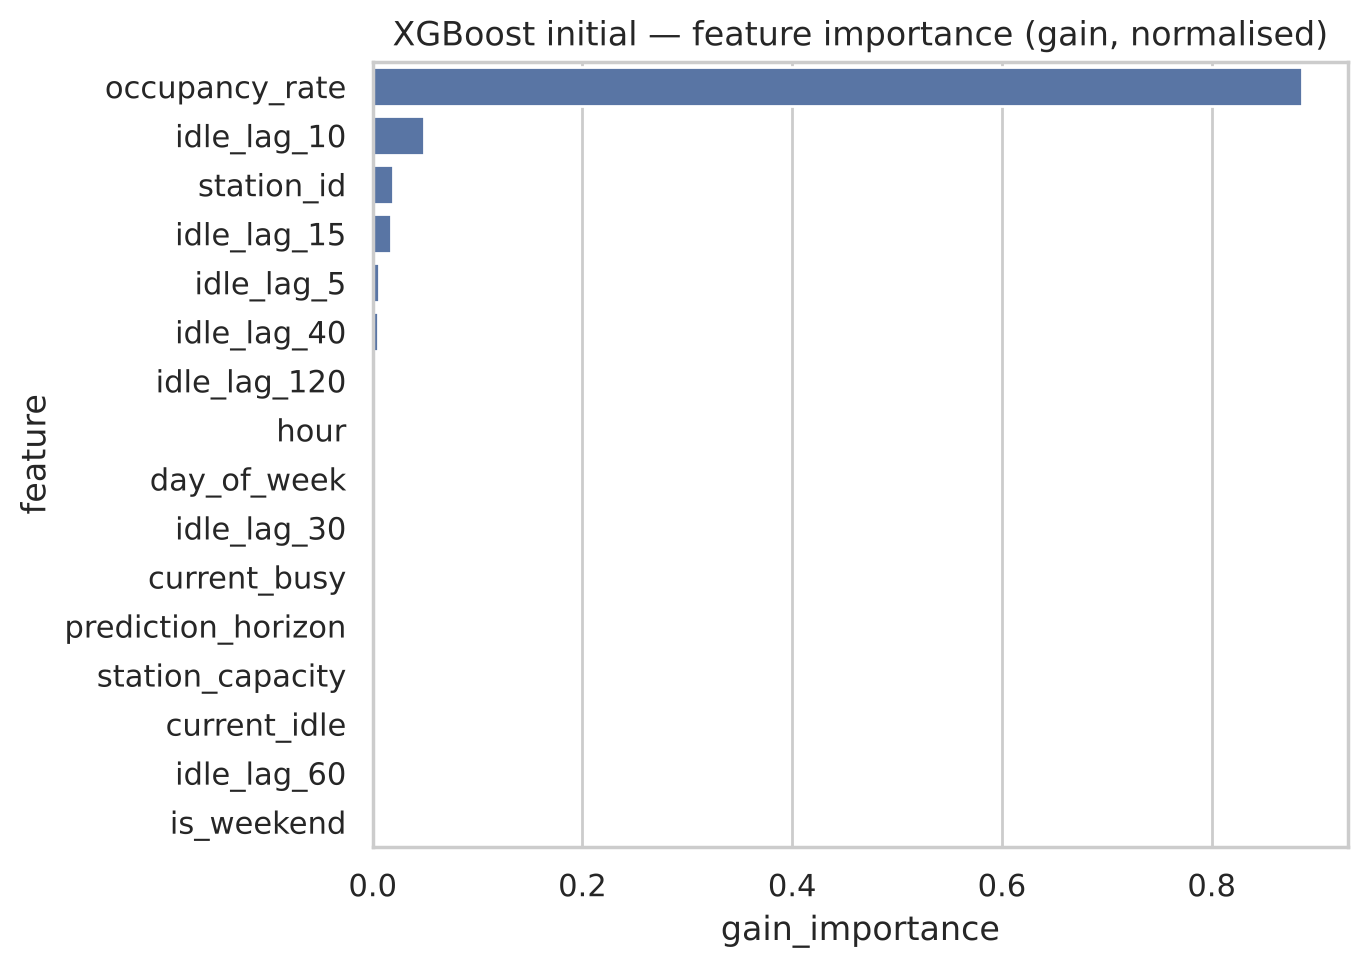

,feature,gain_importance,rank
0,occupancy_rate,0.8857,1
1,idle_lag_10,0.0491,2
2,station_id,0.0193,3
3,idle_lag_15,0.0175,4
4,idle_lag_5,0.0062,5
5,idle_lag_40,0.0049,6
6,idle_lag_120,0.0027,7
7,hour,0.0026,8


In [7]:
# Feature importance of the initial model (gain); one-hot station columns are summed into station_id
pre = pipe_init.named_steps["preprocess"]; model = pipe_init.named_steps["model"]
imp = pd.Series(model.feature_importances_, index=pre.get_feature_names_out())
imp_grp = imp.groupby(lambda n: "station_id" if n.startswith("station_id_") else n).sum().sort_values(ascending=False)
imp_df = imp_grp.rename("gain_importance").reset_index().rename(columns={"index": "feature"})
imp_df["rank"] = np.arange(1, len(imp_df) + 1)
imp_df.to_csv(TABLES / "xgboost_initial_feature_importance.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=imp_df, y="feature", x="gain_importance", color="#4C72B0", ax=ax)
ax.set_title("XGBoost initial — feature importance (gain, normalised)"); fig.tight_layout()
fig.savefig(FIGS / "xgboost_initial_feature_importance.png", dpi=150); plt.show()
imp_df.head(8)

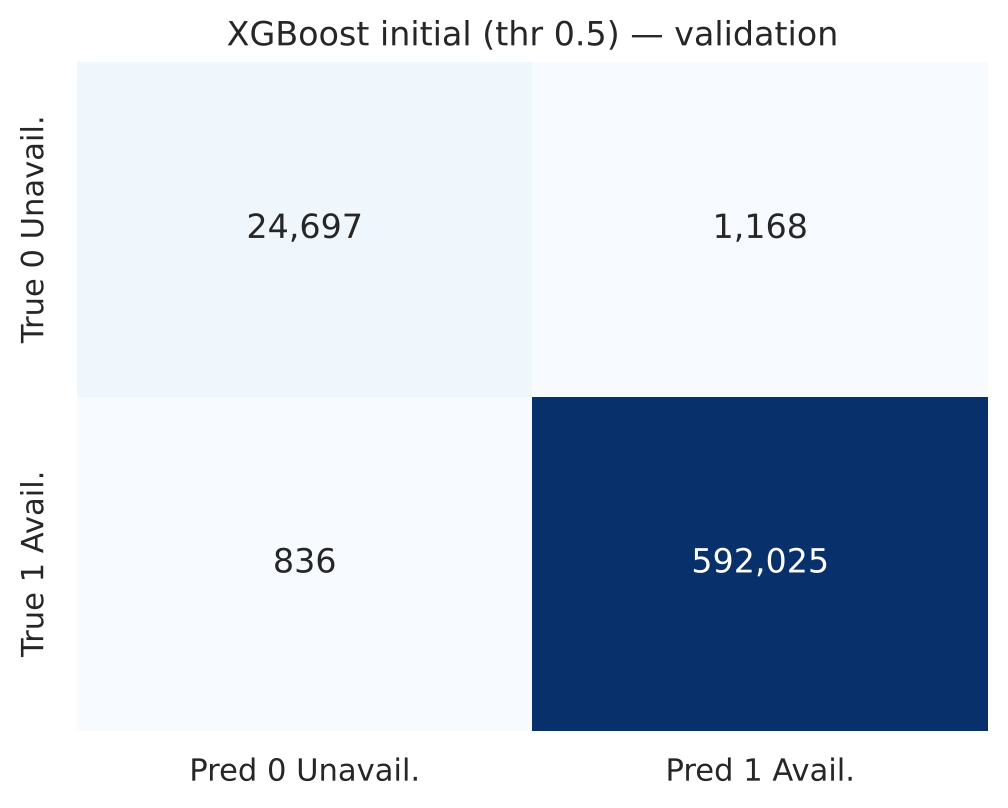

,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,24697,1168,836,592025


In [8]:
def plot_cm(res_list, titles, fname):
    fig, axes = plt.subplots(1, len(res_list), figsize=(5.2 * len(res_list), 4.2))
    axes = np.atleast_1d(axes)
    for ax, r, t in zip(axes, res_list, titles):
        o = r["overall"].iloc[0]
        cm = np.array([[o.actual_0_predicted_0, o.actual_0_predicted_1], [o.actual_1_predicted_0, o.actual_1_predicted_1]])
        sns.heatmap(cm, annot=True, fmt=",.0f", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=["Pred 0 Unavail.", "Pred 1 Avail."], yticklabels=["True 0 Unavail.", "True 1 Avail."])
        ax.set_title(t)
    fig.tight_layout(); fig.savefig(FIGS / fname, dpi=150); plt.show()
plot_cm([res_init], ["XGBoost initial (thr 0.5) — validation"], "xgboost_initial_confusion_matrix.png")
cm_df = res_init["overall"][[c for c in res_init["overall"].columns if c.startswith("actual_")]]
cm_df.to_csv(TABLES / "xgboost_initial_confusion_matrix.csv", index=False); cm_df

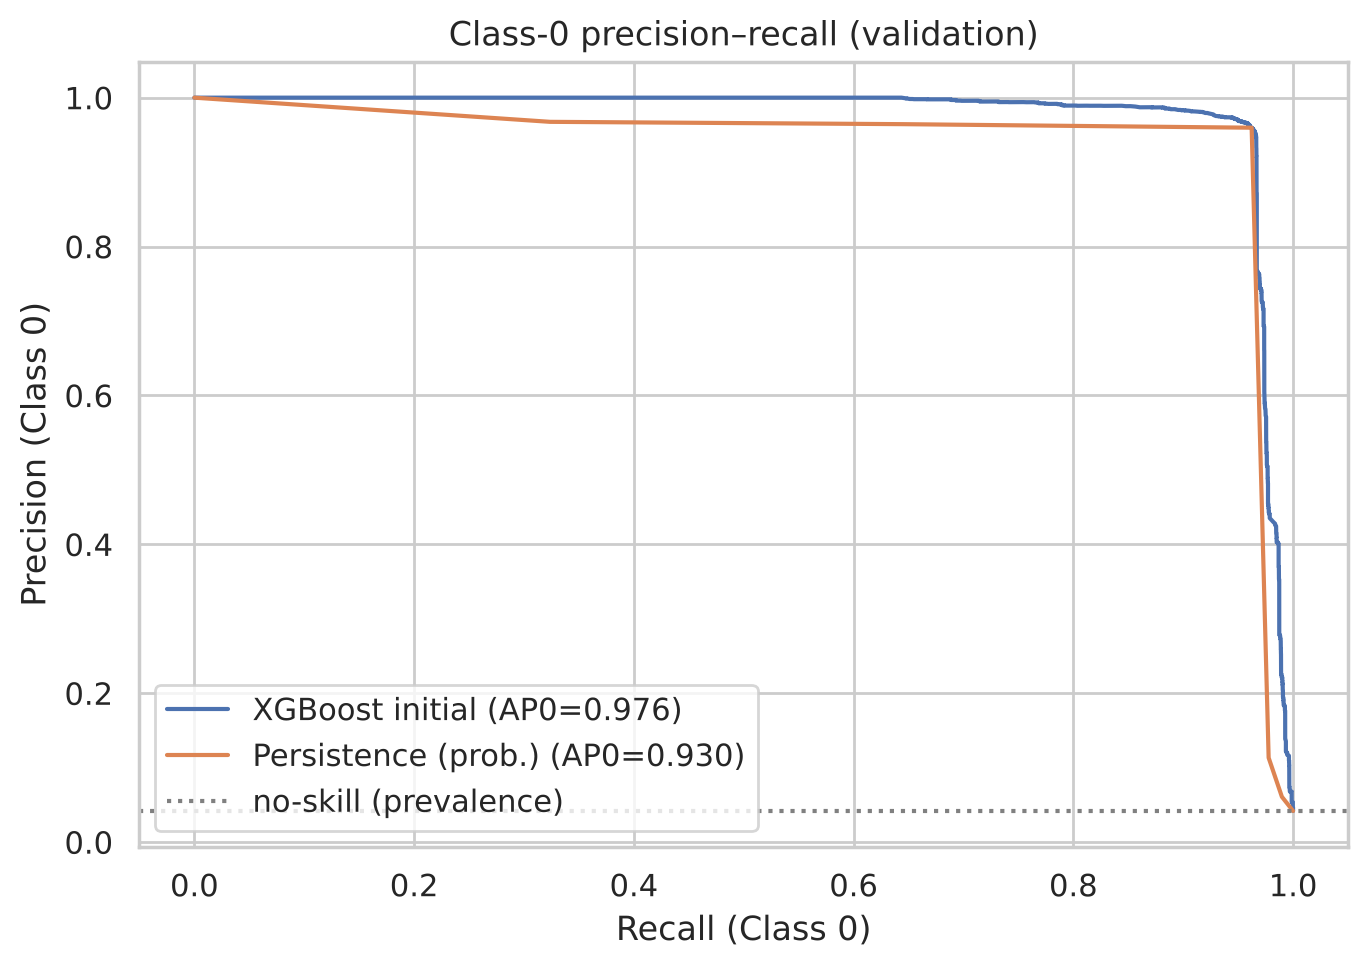

In [9]:
def pr_class0(frames, labels, fname, title):
    fig, ax = plt.subplots(figsize=(7, 5))
    for f, l in zip(frames, labels):
        pr, rc, _ = precision_recall_curve(1 - f.y_true, 1 - f.y_prob)
        ax.plot(rc, pr, label=f"{l} (AP0={ap0(f.y_true, f.y_prob):.3f})")
    ax.axhline(1 - frames[0].y_true.mean(), ls=":", c="grey", label="no-skill (prevalence)")
    ax.set_xlabel("Recall (Class 0)"); ax.set_ylabel("Precision (Class 0)"); ax.set_title(title); ax.legend(loc="lower left")
    fig.tight_layout(); fig.savefig(FIGS / fname, dpi=150); plt.show()
pers = pd.read_parquet(PRED / "persistence_probability_validation_predictions.parquet") if (PRED / "persistence_probability_validation_predictions.parquet").exists() else None
frames = [pred_init] + ([pers] if pers is not None else []); labels = ["XGBoost initial"] + (["Persistence (prob.)"] if pers is not None else [])
pr_class0(frames, labels, "xgboost_initial_pr_curve_class0.png", "Class-0 precision–recall (validation)")

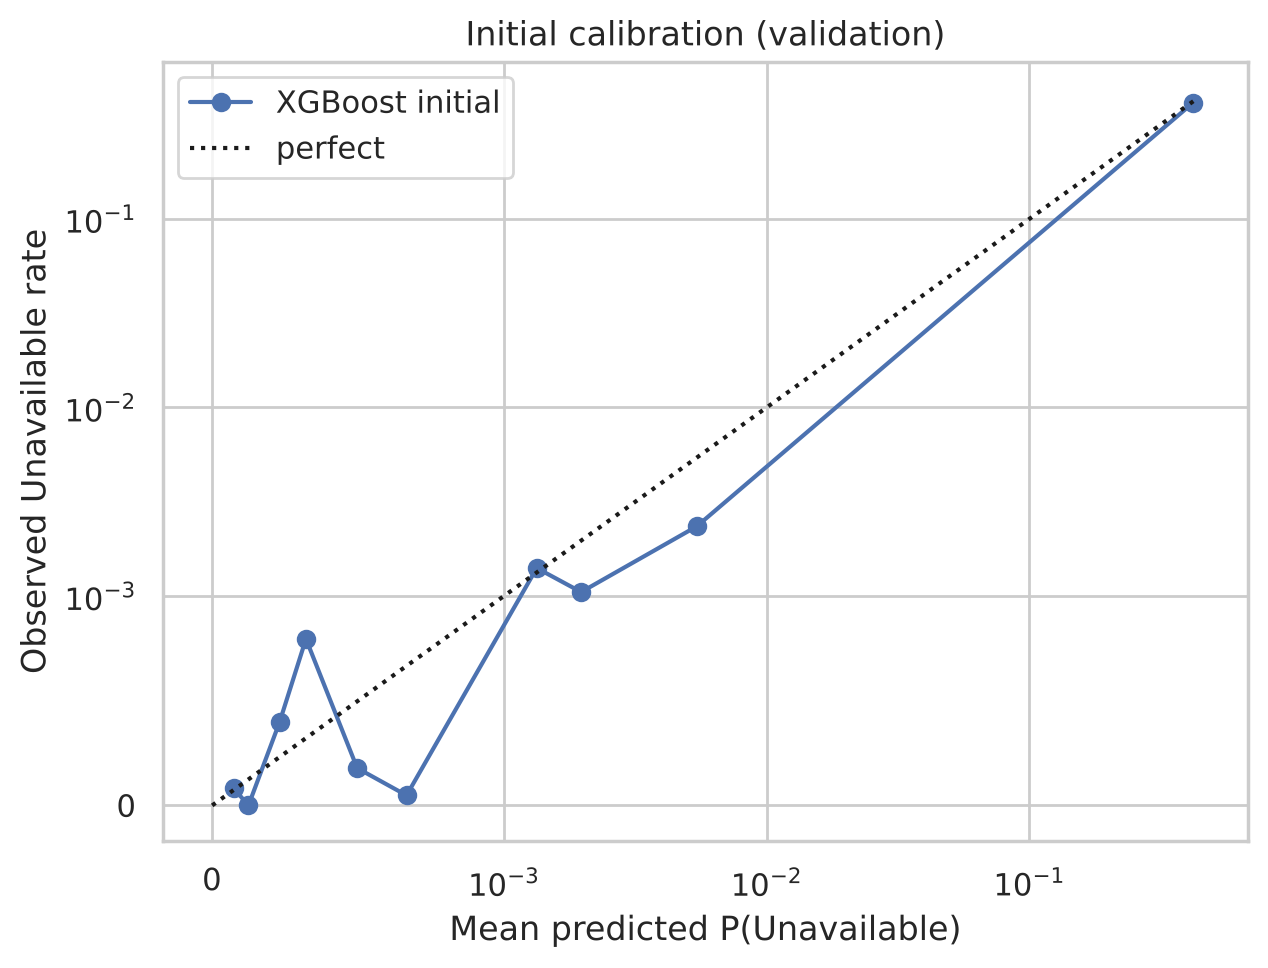

,model,mean_pred_unavailable,observed_unavailable
0,XGBoost initial,0.0001,0.0001
1,XGBoost initial,0.0001,0.0000
2,XGBoost initial,0.0002,0.0004
3,XGBoost initial,0.0003,0.0008
4,XGBoost initial,0.0005,0.0002
5,XGBoost initial,0.0007,0.0000
6,XGBoost initial,0.0013,0.0014
7,XGBoost initial,0.0020,0.0010
8,XGBoost initial,0.0054,0.0023
9,XGBoost initial,0.4197,0.4131


In [10]:
def reliability(frames, labels, fname, title, n_bins=10):
    """Reliability of the Unavailable probability (1 - y_prob), quantile bins (class 0 is rare)."""
    fig, ax = plt.subplots(figsize=(6.5, 5)); tabs = []
    for f, l in zip(frames, labels):
        frac, mean = calibration_curve(1 - f.y_true, 1 - f.y_prob, n_bins=n_bins, strategy="quantile")
        ax.plot(mean, frac, "o-", label=l); tabs.append(pd.DataFrame({"model": l, "mean_pred_unavailable": mean, "observed_unavailable": frac}))
    lim = max(ax.get_xlim()[1], ax.get_ylim()[1]); ax.plot([0, lim], [0, lim], "k:", label="perfect")
    ax.set_xscale("symlog", linthresh=1e-3); ax.set_yscale("symlog", linthresh=1e-3)
    ax.set_xlabel("Mean predicted P(Unavailable)"); ax.set_ylabel("Observed Unavailable rate"); ax.set_title(title); ax.legend()
    fig.tight_layout(); fig.savefig(FIGS / fname, dpi=150); plt.show(); return pd.concat(tabs)
cal_tab = reliability([pred_init], ["XGBoost initial"], "xgboost_initial_calibration.png", "Initial calibration (validation)")
cal_tab

In [11]:
def error_analysis(pred, feats, name):
    d = pred.merge(feats, on=["station_id", "time", "prediction_horizon"], how="left")
    d["fn_missed_unavailable"] = ((d.y_true == 0) & (d.y_pred == 1)).astype(int)     # unavailable predicted available
    d["fp_false_alarm"] = ((d.y_true == 1) & (d.y_pred == 0)).astype(int)
    d["state_now"] = np.where(d.current_idle > 0, "available now", "unavailable now")
    out = {}
    out["by_current_state"] = d.groupby("state_now").agg(n=("y_true", "size"), unavailable=("y_true", lambda s: int((s == 0).sum())),
                                  missed_unavailable=("fn_missed_unavailable", "sum"), false_alarms=("fp_false_alarm", "sum"))
    out["by_horizon"] = d.groupby("prediction_horizon").agg(n=("y_true", "size"), missed_unavailable=("fn_missed_unavailable", "sum"), false_alarms=("fp_false_alarm", "sum"))
    out["by_hour"] = d.groupby("hour").agg(n=("y_true", "size"), missed_unavailable=("fn_missed_unavailable", "sum"), false_alarms=("fp_false_alarm", "sum"))
    out["top_stations"] = d.groupby("station_id").agg(n=("y_true", "size"), unavailable=("y_true", lambda s: int((s == 0).sum())),
                          errors=("fn_missed_unavailable", "sum"), false_alarms=("fp_false_alarm", "sum")).assign(total_errors=lambda x: x.errors + x.false_alarms).sort_values("total_errors", ascending=False).head(10)
    return out
val_feats = validation[["station_id", "time", "prediction_horizon", "hour", "current_idle", "station_capacity"]]
EA_init = error_analysis(pred_init, val_feats, "initial")
for k, v in EA_init.items():
    v.to_csv(TABLES / f"xgboost_initial_error_{k}.csv"); print("\n#", k); display(v.head(10))


# by_current_state


,n,unavailable,missed_unavailable,false_alarms
state_now,,,,
available now,592789,975,972,117
unavailable now,25937,24890,196,719



# by_horizon


,n,missed_unavailable,false_alarms
prediction_horizon,,,
30,206482,329,220
40,206302,372,268
60,205942,467,348



# by_hour


,n,missed_unavailable,false_alarms
hour,,,
0,25848,14,0
1,25848,26,3
2,25848,0,22
3,25848,0,0
4,25878,0,0
5,25884,0,0
6,25884,4,18
7,25884,39,71
8,25884,135,18



# top_stations


,n,unavailable,errors,false_alarms,total_errors
station_id,,,,,
1888,6886,774,175,213,388
1763,6886,2352,202,183,385
1879,6886,771,212,168,380
1897,6886,102,86,26,112
1758,6886,3865,36,65,101
1751,6886,3031,35,55,90
1797,6886,201,66,20,86
1777,6886,54,46,25,71
1802,6886,108,38,26,64


## 5. Optimization (Step 5)
**Protocol.** Hyperparameters are chosen **only** on the Dec 24–29 tuning period (all 91 stations, both targets present for every horizon). Estimators for the search are fitted on the development sample (Dec 1–23, every 4th timestamp) for speed, with early stopping (50 rounds, logloss) on the tuning data. The selection metric is tuning `AP_0`. The search is a greedy coordinate search: each stage fixes the best value of the previous stage. The decisive confirmation (initial vs selected configuration, and `n_estimators`) is run on the full Model Fit data.

In [12]:
TUNE_LOG = []
def run_config(stage, label, params, cols=None, w0=1.0, data=dev, early=True, n_max=1000):
    cols = list(cols or F)
    p = dict(params); p["n_estimators"] = n_max if early else p["n_estimators"]
    pipe = xm.build_xgboost_pipeline(p, cols, n_jobs=N_JOBS)
    w = xm.class0_sample_weights(data.target.to_numpy(), w0) if w0 != 1.0 else None
    pipe, sec = xm.fit_xgboost(pipe, data[cols], data.target.astype(int).to_numpy(), sample_weight=w,
                               eval_set=(splits["tuning"][cols], ytune), early_stopping_rounds=50 if early else None)
    m = pipe.named_steps["model"]
    prob = xm.raw_probability(pipe, splits["tuning"][cols])
    row = {"stage": stage, "config": label, "best_iteration": int(getattr(m, "best_iteration", m.n_estimators - 1)) + 1,
           "tuning_ap0": ap0(ytune, prob), "tuning_brier": brier_score_loss(ytune, prob), "tuning_logloss": log_loss(ytune, np.clip(prob, 1e-7, 1 - 1e-7)),
           "tuning_roc_auc": roc_auc_score(ytune, prob), "fit_seconds": sec, "n_features": len(cols)}
    TUNE_LOG.append(row); print(f"[{stage}] {label:<34} AP0={row['tuning_ap0']:.4f} Brier={row['tuning_brier']:.5f} iters={row['best_iteration']:>4} {sec:5.0f}s")
    return row, pipe

def pick(stage):
    t = pd.DataFrame(TUNE_LOG); t = t[t.stage == stage]
    return t.loc[t.tuning_ap0.idxmax()]

BEST = dict(xm.DEFAULT_XGB_PARAMS); BEST.pop("n_estimators")
BEST_W0 = 1.0

In [13]:
# 5.1 learning rate
for lr in (0.02, 0.05, 0.1, 0.2):
    run_config("1_learning_rate", f"learning_rate={lr}", {**BEST, "learning_rate": lr})
b = pick("1_learning_rate"); BEST["learning_rate"] = float(b.config.split("=")[1]); print("-> learning_rate", BEST["learning_rate"])

[1_learning_rate] learning_rate=0.02                 AP0=0.9837 Brier=0.00164 iters= 408    28s


[1_learning_rate] learning_rate=0.05                 AP0=0.9837 Brier=0.00163 iters= 174    15s


[1_learning_rate] learning_rate=0.1                  AP0=0.9839 Brier=0.00163 iters=  84    10s


[1_learning_rate] learning_rate=0.2                  AP0=0.9839 Brier=0.00164 iters=  33     7s
-> learning_rate 0.1


In [14]:
# 5.2 max_depth
for d in (3, 4, 6, 8):
    run_config("2_max_depth", f"max_depth={d}", {**BEST, "max_depth": d})
BEST["max_depth"] = int(pick("2_max_depth").config.split("=")[1]); print("-> max_depth", BEST["max_depth"])

[2_max_depth] max_depth=3                        AP0=0.9836 Brier=0.00166 iters= 114    10s


[2_max_depth] max_depth=4                        AP0=0.9839 Brier=0.00163 iters=  84     9s


[2_max_depth] max_depth=6                        AP0=0.9838 Brier=0.00165 iters=  59     9s


[2_max_depth] max_depth=8                        AP0=0.9843 Brier=0.00175 iters=  51     9s
-> max_depth 8


In [15]:
# 5.3 min_child_weight
for v in (1, 5, 20, 50):
    run_config("3_min_child_weight", f"min_child_weight={v}", {**BEST, "min_child_weight": v})
BEST["min_child_weight"] = int(pick("3_min_child_weight").config.split("=")[1]); print("-> min_child_weight", BEST["min_child_weight"])

[3_min_child_weight] min_child_weight=1                 AP0=0.9843 Brier=0.00175 iters=  51     9s


[3_min_child_weight] min_child_weight=5                 AP0=0.9844 Brier=0.00173 iters=  52     9s


[3_min_child_weight] min_child_weight=20                AP0=0.9839 Brier=0.00170 iters=  56     9s


[3_min_child_weight] min_child_weight=50                AP0=0.9833 Brier=0.00173 iters=  59     9s
-> min_child_weight 5


In [16]:
# 5.4 subsample, 5.5 colsample_bytree
for v in (0.6, 0.8, 1.0):
    run_config("4_subsample", f"subsample={v}", {**BEST, "subsample": v})
BEST["subsample"] = float(pick("4_subsample").config.split("=")[1])
for v in (0.6, 0.8, 1.0):
    run_config("5_colsample_bytree", f"colsample_bytree={v}", {**BEST, "colsample_bytree": v})
BEST["colsample_bytree"] = float(pick("5_colsample_bytree").config.split("=")[1])
print("-> subsample", BEST["subsample"], "| colsample_bytree", BEST["colsample_bytree"])

[4_subsample] subsample=0.6                      AP0=0.9840 Brier=0.00173 iters=  54     8s


[4_subsample] subsample=0.8                      AP0=0.9840 Brier=0.00173 iters=  54    11s


[4_subsample] subsample=1.0                      AP0=0.9844 Brier=0.00173 iters=  52     7s


[5_colsample_bytree] colsample_bytree=0.6               AP0=0.9843 Brier=0.00168 iters=  62     8s


[5_colsample_bytree] colsample_bytree=0.8               AP0=0.9847 Brier=0.00173 iters=  53     8s


[5_colsample_bytree] colsample_bytree=1.0               AP0=0.9844 Brier=0.00173 iters=  52     8s
-> subsample 1.0 | colsample_bytree 0.8


In [17]:
# 5.6 L1 / L2 regularisation
for v in (0.0, 0.1, 1.0, 5.0):
    run_config("6a_reg_alpha", f"reg_alpha={v}", {**BEST, "reg_alpha": v})
BEST["reg_alpha"] = float(pick("6a_reg_alpha").config.split("=")[1])
for v in (1.0, 5.0, 20.0):
    run_config("6b_reg_lambda", f"reg_lambda={v}", {**BEST, "reg_lambda": v})
BEST["reg_lambda"] = float(pick("6b_reg_lambda").config.split("=")[1])
print("-> reg_alpha", BEST["reg_alpha"], "| reg_lambda", BEST["reg_lambda"])

[6a_reg_alpha] reg_alpha=0.0                      AP0=0.9847 Brier=0.00173 iters=  53     8s


[6a_reg_alpha] reg_alpha=0.1                      AP0=0.9845 Brier=0.00173 iters=  54     9s


[6a_reg_alpha] reg_alpha=1.0                      AP0=0.9848 Brier=0.00172 iters=  56     9s


[6a_reg_alpha] reg_alpha=5.0                      AP0=0.9846 Brier=0.00171 iters=  55     9s


[6b_reg_lambda] reg_lambda=1.0                     AP0=0.9848 Brier=0.00172 iters=  56    10s


[6b_reg_lambda] reg_lambda=5.0                     AP0=0.9846 Brier=0.00172 iters=  55     9s


[6b_reg_lambda] reg_lambda=20.0                    AP0=0.9843 Brier=0.00170 iters=  73    10s
-> reg_alpha 1.0 | reg_lambda 1.0


### 5.7 Class-imbalance handling
Only ~4–5 % of rows are Unavailable (class 0). Because the label is `1 = Available`, XGBoost's `scale_pos_weight` would act on the **available** class, i.e. the wrong direction for our goal, so it is **not** used. Instead the class-0 rows receive a sample weight `w0` (label definition unchanged, nothing is resampled or deleted). Weighted training distorts probabilities, which is why the calibration step below is applied afterwards.

In [18]:
for w0 in (1.0, 2.0, 5.0, 10.0):
    run_config("7_class0_weight", f"class0_weight={w0}", BEST, w0=w0)
BEST_W0 = float(pick("7_class0_weight").config.split("=")[1]); print("-> class0 sample weight", BEST_W0)

[7_class0_weight] class0_weight=1.0                  AP0=0.9848 Brier=0.00172 iters=  56     9s


[7_class0_weight] class0_weight=2.0                  AP0=0.9847 Brier=0.00187 iters=  55     9s


[7_class0_weight] class0_weight=5.0                  AP0=0.9844 Brier=0.00237 iters=  61     9s


[7_class0_weight] class0_weight=10.0                 AP0=0.9835 Brier=0.00293 iters=  69     9s
-> class0 sample weight 1.0


### 5.8 Feature selection
Candidate sets are built from the initial importance table and domain redundancy (`occupancy_rate = current_busy / capacity`, `current_busy = capacity − current_idle`). Rule: highest tuning `AP_0`; a smaller set within 0.0005 of the best is preferred.

In [19]:
order = [f for f in imp_df.feature if f != "station_id"]
FS = {
  "all_16": F,
  "no_station_id": [c for c in F if c != "station_id"],
  "no_redundant (-current_busy,-occupancy_rate)": [c for c in F if c not in ("current_busy", "occupancy_rate")],
  "no_calendar (-hour,-day_of_week,-is_weekend)": [c for c in F if c not in ("hour", "day_of_week", "is_weekend")],
  "no_long_lags (-lag_60,-lag_120)": [c for c in F if c not in ("idle_lag_60", "idle_lag_120")],
  "top10_by_importance": ["station_id"] + [c for c in order if c != "prediction_horizon"][:8] + ["prediction_horizon"],
}
for k, cols in FS.items():
    run_config("8_feature_set", k, BEST, cols=cols, w0=BEST_W0)
t = pd.DataFrame(TUNE_LOG); t = t[t.stage == "8_feature_set"].sort_values("tuning_ap0", ascending=False)
top = t.tuning_ap0.max(); cand = t[t.tuning_ap0 >= top - 0.0005].sort_values("n_features")
SELECTED_SET_NAME = cand.iloc[0].config; SELECTED_COLS = FS[SELECTED_SET_NAME]
print("-> feature set:", SELECTED_SET_NAME, f"({len(SELECTED_COLS)} features)")

[8_feature_set] all_16                             AP0=0.9848 Brier=0.00172 iters=  56     8s


[8_feature_set] no_station_id                      AP0=0.9831 Brier=0.00168 iters=  55     3s


[8_feature_set] no_redundant (-current_busy,-occupancy_rate) AP0=0.9848 Brier=0.00176 iters=  55     8s


[8_feature_set] no_calendar (-hour,-day_of_week,-is_weekend) AP0=0.9827 Brier=0.00171 iters= 128    12s


[8_feature_set] no_long_lags (-lag_60,-lag_120)    AP0=0.9843 Brier=0.00171 iters=  55     8s


[8_feature_set] top10_by_importance                AP0=0.9843 Brier=0.00173 iters=  55     7s
-> feature set: no_redundant (-current_busy,-occupancy_rate) (14 features)


### 5.9 Confirmation on the full Model Fit period (Dec 1–23) and `n_estimators` comparison
Selected configuration vs the initial configuration, both trained on all 1.79 M Model Fit rows and scored on the tuning period. `n_estimators` is compared on a 1000-tree model by `AP_0` at several iteration counts.

In [20]:
SEL = {**BEST}
rows = []
pipe_big = xm.build_xgboost_pipeline({**SEL, "n_estimators": 1000}, SELECTED_COLS, n_jobs=N_JOBS)
w = xm.class0_sample_weights(mf.target.to_numpy(), BEST_W0) if BEST_W0 != 1.0 else None
pipe_big, sec_big = xm.fit_xgboost(pipe_big, mf[SELECTED_COLS], mf.target.astype(int).to_numpy(), sample_weight=w)
pre_b, mdl_b = pipe_big.named_steps["preprocess"], pipe_big.named_steps["model"]
Xt_b = pre_b.transform(splits["tuning"][SELECTED_COLS])
for n in (100, 200, 300, 400, 600, 800, 1000):
    pr = mdl_b.predict_proba(Xt_b, iteration_range=(0, n))[:, 1]
    rows.append({"n_estimators": n, "tuning_ap0": ap0(ytune, pr), "tuning_brier": brier_score_loss(ytune, pr),
                 "tuning_logloss": log_loss(ytune, np.clip(pr, 1e-7, 1 - 1e-7))})
nest = pd.DataFrame(rows); nest.to_csv(TABLES / "xgboost_n_estimators_comparison.csv", index=False)
print(f"1000-tree fit on full Model Fit: {sec_big:.0f}s"); display(nest)
bt = nest.tuning_ap0.max(); N_SEL = int(nest[nest.tuning_ap0 >= bt - 0.0005].n_estimators.min())
SEL["n_estimators"] = N_SEL; print("-> n_estimators =", N_SEL)
init_row = {"config": "initial (lr .05, depth 4, 200 trees)", "tuning_ap0": ap0(ytune, xm.raw_probability(pipe_init, Xtune)),
            "tuning_brier": brier_score_loss(ytune, xm.raw_probability(pipe_init, Xtune))}
prsel = mdl_b.predict_proba(Xt_b, iteration_range=(0, N_SEL))[:, 1]
sel_row = {"config": f"selected ({N_SEL} trees)", "tuning_ap0": ap0(ytune, prsel), "tuning_brier": brier_score_loss(ytune, prsel)}
display(pd.DataFrame([init_row, sel_row]))

1000-tree fit on full Model Fit: 137s


,n_estimators,tuning_ap0,tuning_brier,tuning_logloss
0,100,0.9836,0.0018,0.0115
1,200,0.9832,0.0020,0.0134
2,300,0.9828,0.0022,0.0146
3,400,0.9825,0.0022,0.0154
4,600,0.9820,0.0024,0.0165
5,800,0.9817,0.0024,0.0171
6,1000,0.9815,0.0025,0.0175


-> n_estimators = 100


,config,tuning_ap0,tuning_brier
0,"initial (lr .05, depth 4, 200 trees)",0.9835,0.0016
1,selected (100 trees),0.9836,0.0018


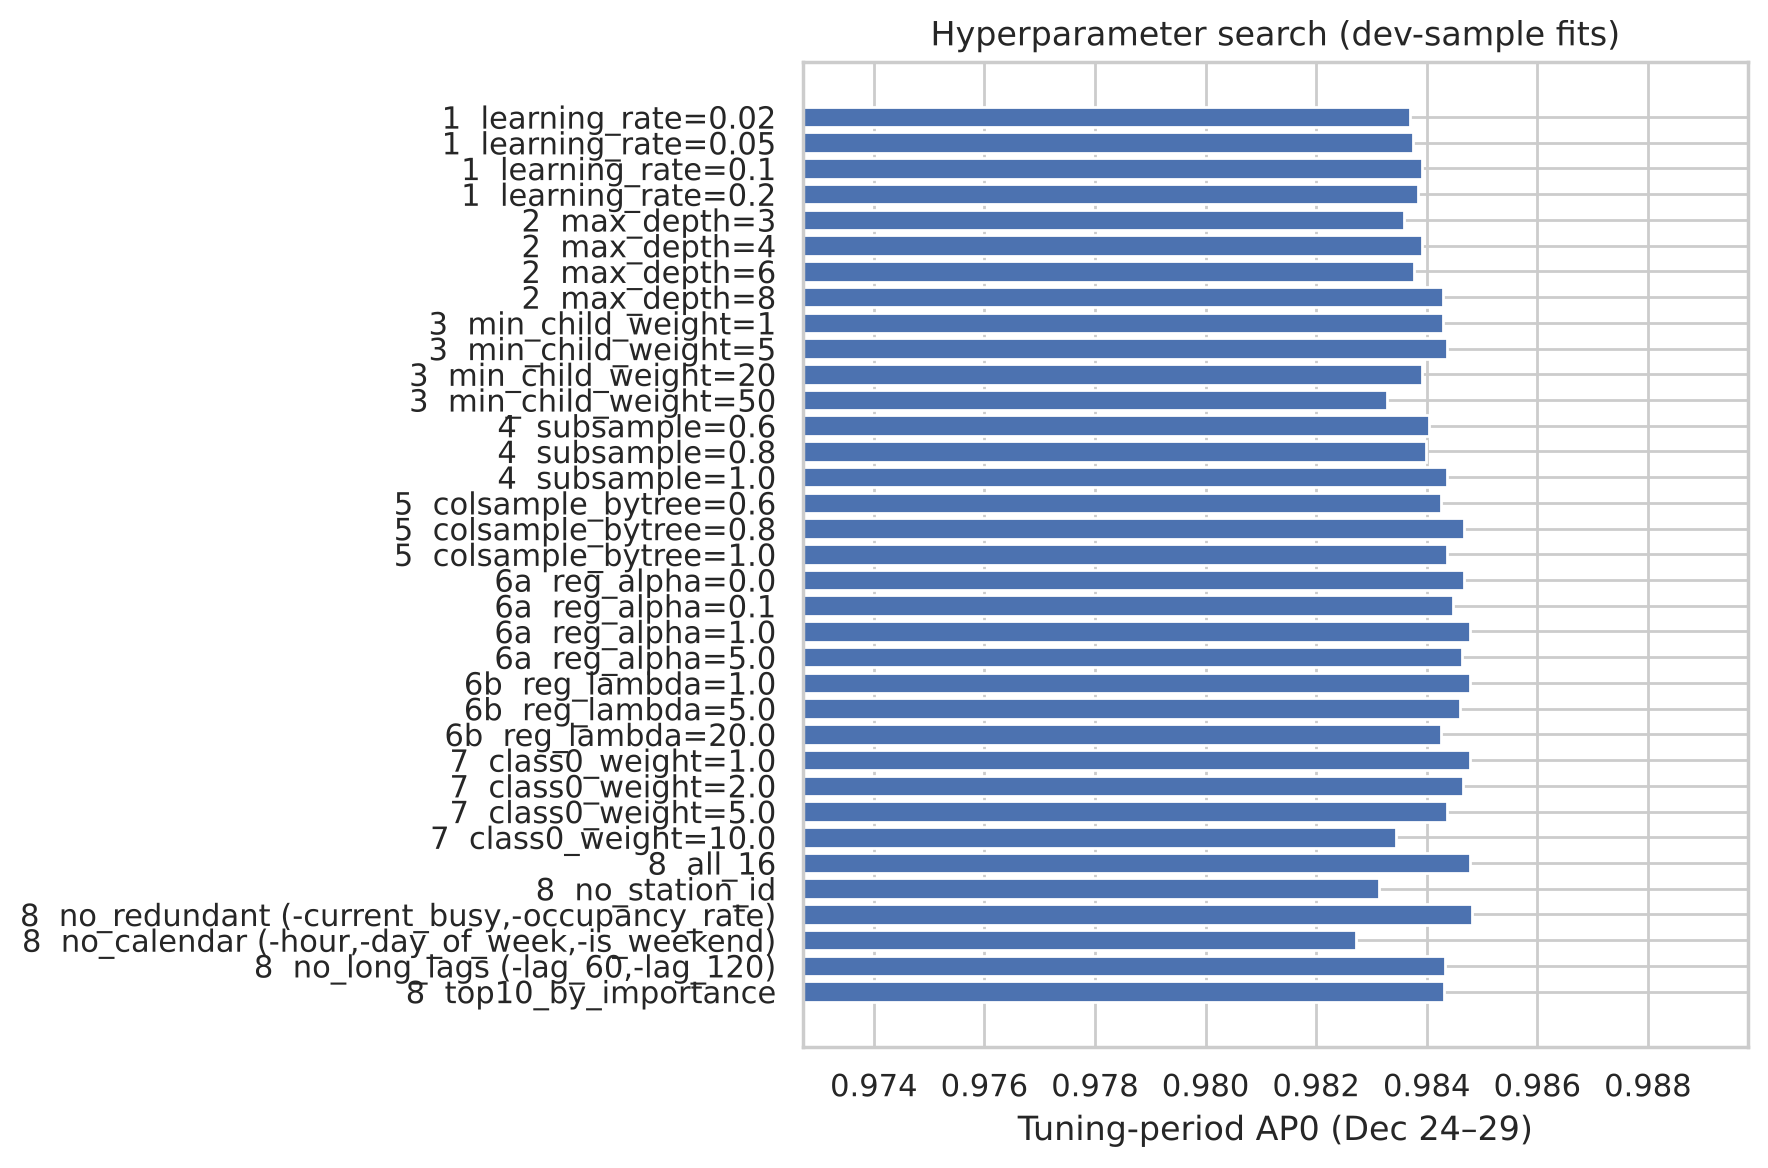

{
  "objective": "binary:logistic",
  "tree_method": "hist",
  "learning_rate": 0.1,
  "max_depth": 8,
  "min_child_weight": 5,
  "subsample": 1.0,
  "colsample_bytree": 0.8,
  "reg_alpha": 1.0,
  "reg_lambda": 1.0,
  "eval_metric": "logloss",
  "random_state": 42,
  "n_estimators": 100,
  "class0_sample_weight": 1.0,
  "feature_set": "no_redundant (-current_busy,-occupancy_rate)",
  "features": [
    "station_id",
    "hour",
    "day_of_week",
    "is_weekend",
    "current_idle",
    "station_capacity",
    "idle_lag_5",
    "idle_lag_10",
    "idle_lag_15",
    "idle_lag_30",
    "idle_lag_40",
    "idle_lag_60",
    "idle_lag_120",
    "prediction_horizon"
  ]
}


In [21]:
tune_df = pd.DataFrame(TUNE_LOG); tune_df.to_csv(TABLES / "xgboost_hyperparameter_tuning_results.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 6))
tt = tune_df.copy(); tt["label"] = tt.stage.str.split("_", n=1).str[0] + "  " + tt.config
ax.barh(tt.label[::-1], tt.tuning_ap0[::-1], color="#4C72B0"); ax.set_xlim(tt.tuning_ap0.min() - 0.01, tt.tuning_ap0.max() + 0.005)
ax.set_xlabel("Tuning-period AP0 (Dec 24–29)"); ax.set_title("Hyperparameter search (dev-sample fits)"); fig.tight_layout()
fig.savefig(FIGS / "xgboost_tuning_results.png", dpi=150); plt.show()
selected_config = {**SEL, "class0_sample_weight": BEST_W0, "feature_set": SELECTED_SET_NAME, "features": SELECTED_COLS}
print(json.dumps(selected_config, indent=2))

## 6. Refit on Dec 1–29
The selected estimator is refit on Model Fit + Tuning data (Dec 1–29, both timestamps inside). The calibration (Dec 30–Jan 2) and threshold (Jan 3–5) periods are **not** used for fitting.

In [22]:
w = xm.class0_sample_weights(fit_tuning.target.to_numpy(), BEST_W0) if BEST_W0 != 1.0 else None
pipe_opt = xm.build_xgboost_pipeline(SEL, SELECTED_COLS, n_jobs=N_JOBS)
pipe_opt, TRAIN_SEC_OPT = xm.fit_xgboost(pipe_opt, fit_tuning[SELECTED_COLS], fit_tuning.target.astype(int).to_numpy(), sample_weight=w)
print(f"refit on {len(fit_tuning):,} rows in {TRAIN_SEC_OPT:.0f}s")

refit on 2,259,325 rows in 25s


## 7. Probability calibration (Dec 30–Jan 2) — estimator is not refit
Methods compared: none / sigmoid (Platt on the logit) / isotonic. To compare fairly, each calibrator is fit on Dec 30–31 and scored on Jan 1–2; the chosen method is then refit on the whole calibration period. Selection: lowest Brier score, tie-break by log-loss.

In [23]:
cal = splits["calibration"]; ycal = cal.target.astype(int).to_numpy()
raw_cal = xm.raw_probability(pipe_opt, cal[SELECTED_COLS])
first = (cal.time < "2023-01-01").to_numpy() & (cal.target_time < "2023-01-01").to_numpy(); second = (cal.time >= "2023-01-01").to_numpy()
def cal_metrics(y, p): return {"brier": brier_score_loss(y, p), "logloss": log_loss(y, np.clip(p, 1e-7, 1 - 1e-7)), "ap0": ap0(y, p), "roc_auc": roc_auc_score(y, p)}
rows = [{"method": "none", **cal_metrics(ycal[second], raw_cal[second])}]
for meth in ("sigmoid", "isotonic"):
    c = xm.fit_calibrator(raw_cal[first], ycal[first], meth)
    rows.append({"method": meth, **cal_metrics(ycal[second], xm.apply_calibrator(c, raw_cal[second]))})
cal_cmp = pd.DataFrame(rows); cal_cmp.to_csv(TABLES / "xgboost_calibration_method_comparison.csv", index=False)
display(cal_cmp)
CAL_METHOD = cal_cmp.sort_values(["brier", "logloss"]).iloc[0].method
print("selected:", CAL_METHOD)
calibrator = xm.fit_calibrator(raw_cal, ycal, CAL_METHOD) if CAL_METHOD != "none" else None

,method,brier,logloss,ap0,roc_auc
0,none,0.0017,0.0094,0.9834,0.9954
1,sigmoid,0.0024,0.0111,0.9834,0.9954
2,isotonic,0.0021,0.0173,0.9674,0.9923


selected: none


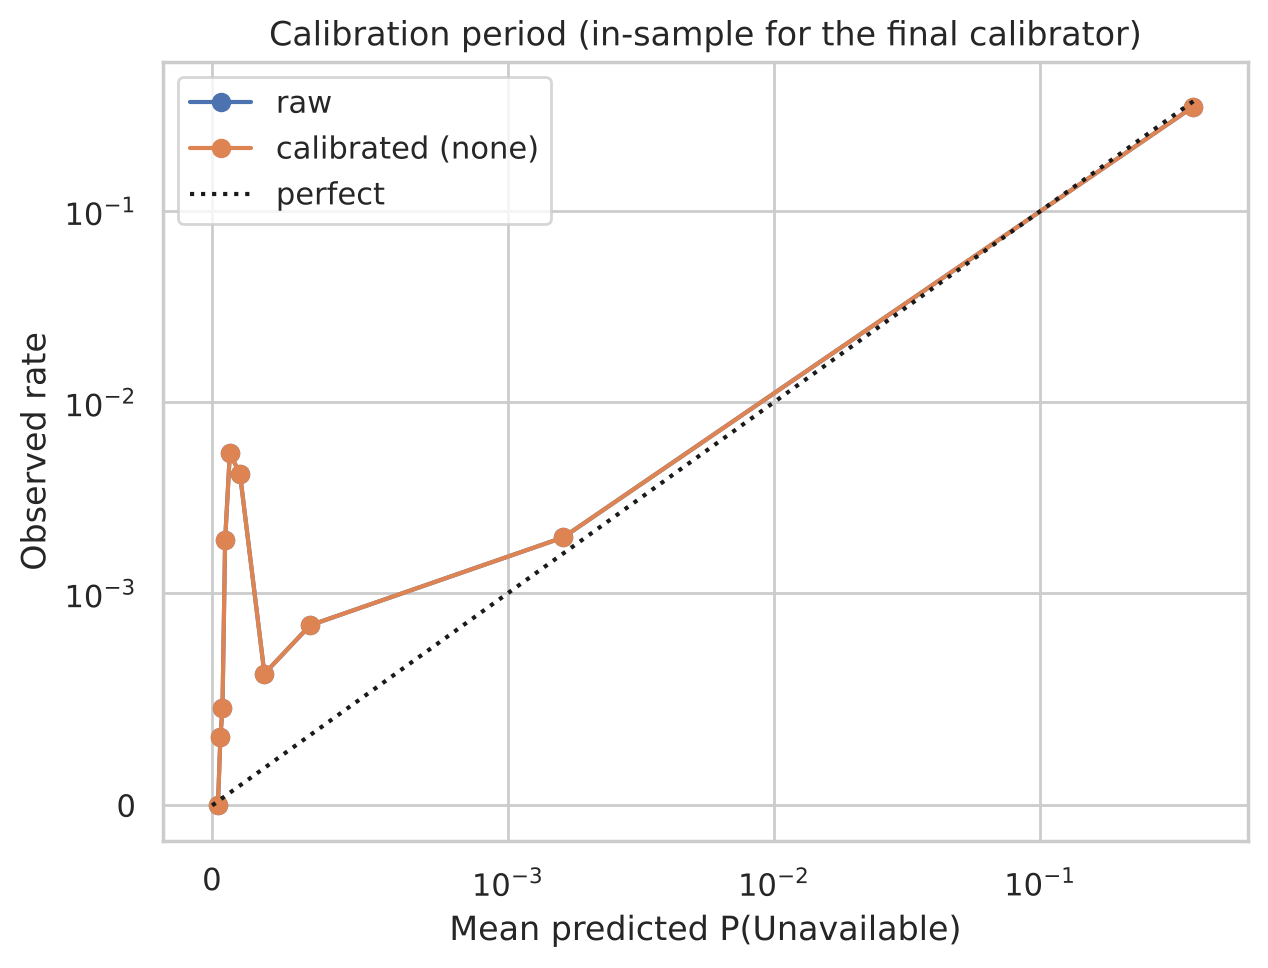

In [24]:
rf = xm.apply_calibrator(calibrator, raw_cal)
fig, ax = plt.subplots(figsize=(6.5, 5))
for p_, l in ((raw_cal, "raw"), (rf, f"calibrated ({CAL_METHOD})")):
    fr, me = calibration_curve(1 - ycal, 1 - p_, n_bins=10, strategy="quantile"); ax.plot(me, fr, "o-", label=l)
lim = max(ax.get_xlim()[1], ax.get_ylim()[1]); ax.plot([0, lim], [0, lim], "k:", label="perfect")
ax.set_xscale("symlog", linthresh=1e-3); ax.set_yscale("symlog", linthresh=1e-3)
ax.set_xlabel("Mean predicted P(Unavailable)"); ax.set_ylabel("Observed rate"); ax.set_title("Calibration period (in-sample for the final calibrator)"); ax.legend()
fig.tight_layout(); fig.savefig(FIGS / "xgboost_optimized_calibration_period.png", dpi=150); plt.show()

## 8. Threshold optimization (Jan 3–5)
Class 0 is predicted when `y_prob < threshold`. The threshold maximising **Class-0 F1** on the threshold period is chosen (ties → closest to 0.5), then frozen.

selected threshold 0.53 | threshold-period Class-0 F1 0.9280 (at 0.5: 0.9275) | AP0 0.9430


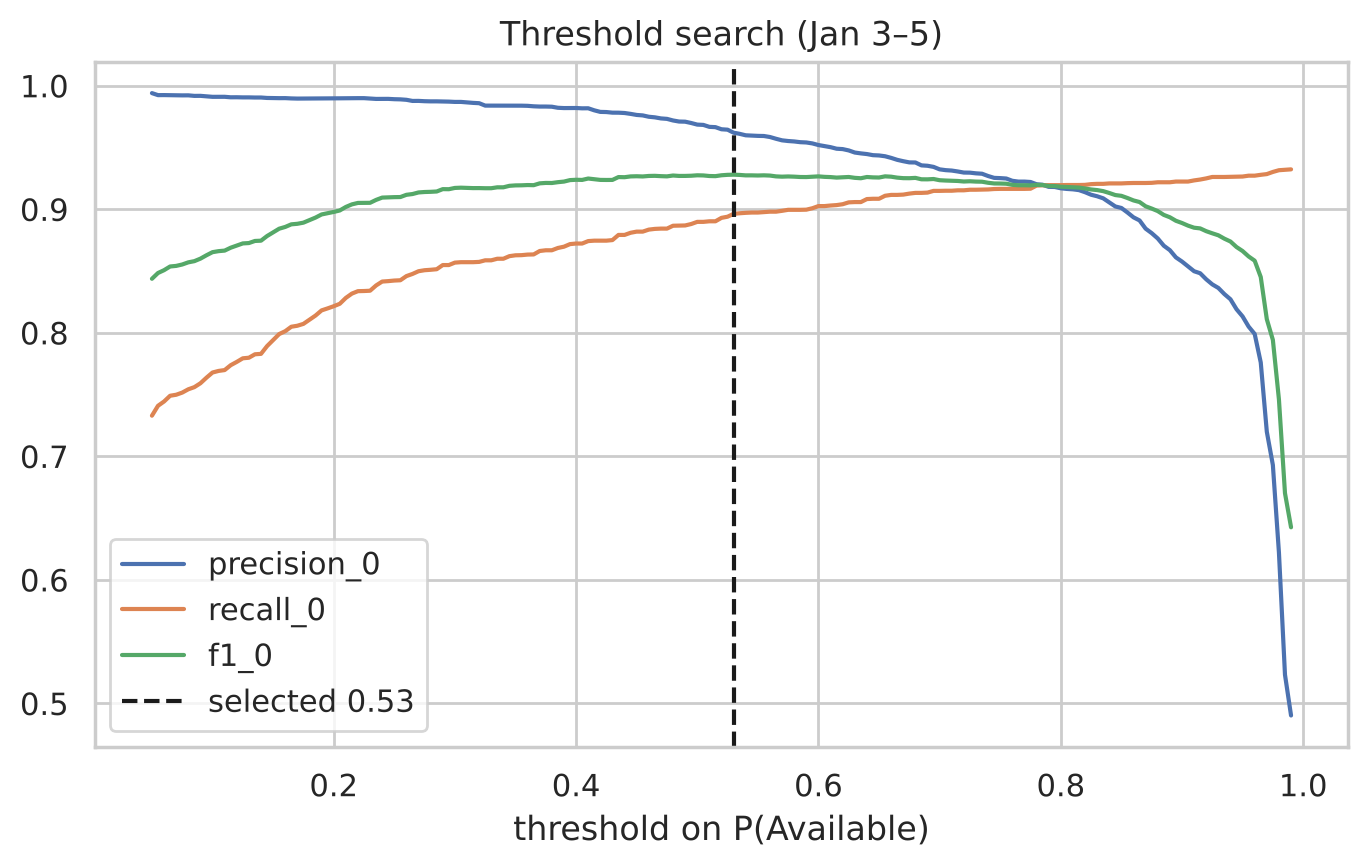

In [25]:
th = splits["threshold"]; yth = th.target.astype(int).to_numpy()
pth = xm.apply_calibrator(calibrator, xm.raw_probability(pipe_opt, th[SELECTED_COLS]))
grid = np.round(np.arange(0.05, 0.995, 0.005), 3); rows = []
for t_ in grid:
    pred1 = pth >= t_; tp0 = ((yth == 0) & ~pred1).sum(); fp0 = ((yth == 1) & ~pred1).sum(); fn0 = ((yth == 0) & pred1).sum()
    pr_ = tp0 / (tp0 + fp0) if tp0 + fp0 else np.nan; rc_ = tp0 / (tp0 + fn0) if tp0 + fn0 else np.nan
    f1 = 2 * pr_ * rc_ / (pr_ + rc_) if (pr_ == pr_ and rc_ == rc_ and pr_ + rc_ > 0) else 0.0
    rows.append({"threshold": t_, "precision_0": pr_, "recall_0": rc_, "f1_0": f1})
thr_df = pd.DataFrame(rows); thr_df.to_csv(TABLES / "xgboost_threshold_search.csv", index=False)
best = thr_df.f1_0.max(); cands = thr_df[thr_df.f1_0 >= best - 1e-12]
THRESHOLD = float(cands.iloc[(cands.threshold - 0.5).abs().argsort()].iloc[0].threshold)
f05 = float(thr_df.loc[thr_df.threshold == 0.5, "f1_0"].iloc[0]) if (thr_df.threshold == 0.5).any() else np.nan
print(f"selected threshold {THRESHOLD} | threshold-period Class-0 F1 {best:.4f} (at 0.5: {f05:.4f}) | AP0 {ap0(yth, pth):.4f}")
fig, ax = plt.subplots(figsize=(7, 4.5))
for c_ in ("precision_0", "recall_0", "f1_0"): ax.plot(thr_df.threshold, thr_df[c_], label=c_)
ax.axvline(THRESHOLD, c="k", ls="--", label=f"selected {THRESHOLD}"); ax.set_xlabel("threshold on P(Available)"); ax.legend(); ax.set_title("Threshold search (Jan 3–5)")
fig.tight_layout(); fig.savefig(FIGS / "xgboost_threshold_search.png", dpi=150); plt.show()

## 9. Freeze and save artifacts
Model, preprocessing/encoder, calibrator and threshold are frozen. Large objects go to `outputs/models/` (git-ignored, shared via the team artifact folder).

In [26]:
FROZEN = {"params": SEL, "class0_sample_weight": BEST_W0, "features": SELECTED_COLS, "calibration_method": CAL_METHOD, "threshold": THRESHOLD}
art_opt = xm.make_artifact(pipe_opt, "optimized", threshold=THRESHOLD, calibrator=calibrator, feature_columns=SELECTED_COLS,
                           extra={"fit_period": "2022-12-01..2022-12-29", "fit_rows": len(fit_tuning), **{k: v for k, v in FROZEN.items() if k != "features"}})
xm.save_xgboost_artifact(art_init, MODELS / "xgboost_initial.joblib")
xm.save_xgboost_artifact(art_opt, MODELS / "xgboost_optimized.joblib")
joblib.dump(pipe_init.named_steps["preprocess"], MODELS / "xgboost_initial_preprocessor.joblib")
joblib.dump(pipe_opt.named_steps["preprocess"], MODELS / "xgboost_optimized_preprocessor.joblib")
if calibrator is not None: joblib.dump(calibrator, MODELS / "xgboost_optimized_calibrator.joblib")
pipe_opt.named_steps["model"].save_model(str(MODELS / "xgboost_optimized_booster.json"))
pred_opt, INFER_SEC_OPT = xm.build_prediction_frame(validation, art_opt)
print(f"optimized inference on {len(validation):,} rows: {INFER_SEC_OPT:.1f}s")
print({p.name: f"{p.stat().st_size/1e6:.1f} MB" for p in sorted(MODELS.glob("xgboost_*"))})

optimized inference on 618,726 rows: 0.7s
{'xgboost_initial.joblib': '0.3 MB', 'xgboost_initial_preprocessor.joblib': '0.0 MB', 'xgboost_optimized.joblib': '0.6 MB', 'xgboost_optimized_booster.json': '0.9 MB', 'xgboost_optimized_preprocessor.joblib': '0.0 MB'}


## 10. Optimized validation evaluation
Same 618,726 validation observations as every other model (unseen station 1948 included).

Saved: /home/claude/repo/outputs/tables/xgboost_optimized_overall.csv
Saved: /home/claude/repo/outputs/tables/xgboost_optimized_by_horizon.csv
Saved: /home/claude/repo/outputs/tables/xgboost_optimized_by_station_group.csv


,model_version,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score
0,optimized,618726,0.9963,0.9719,0.9662,0.9452,0.9556,0.9943,0.9750,0.0033


,evaluation_group,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score
0,seen,612854,0.9963,0.9721,0.9662,0.9456,0.9558,0.9945,0.9755,0.0033
1,unseen,5872,0.9980,0.5000,NaN,0.0000,0.0000,0.7324,0.0051,0.0021


,prediction_horizon,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score
0,30,206482,0.9970,0.9782,0.9712,0.9576,0.9644,0.9964,0.9808,0.0027
1,40,206302,0.9965,0.9731,0.9688,0.9475,0.9580,0.9955,0.9772,0.0031
2,60,205942,0.9954,0.9643,0.9586,0.9304,0.9443,0.9907,0.9669,0.0040


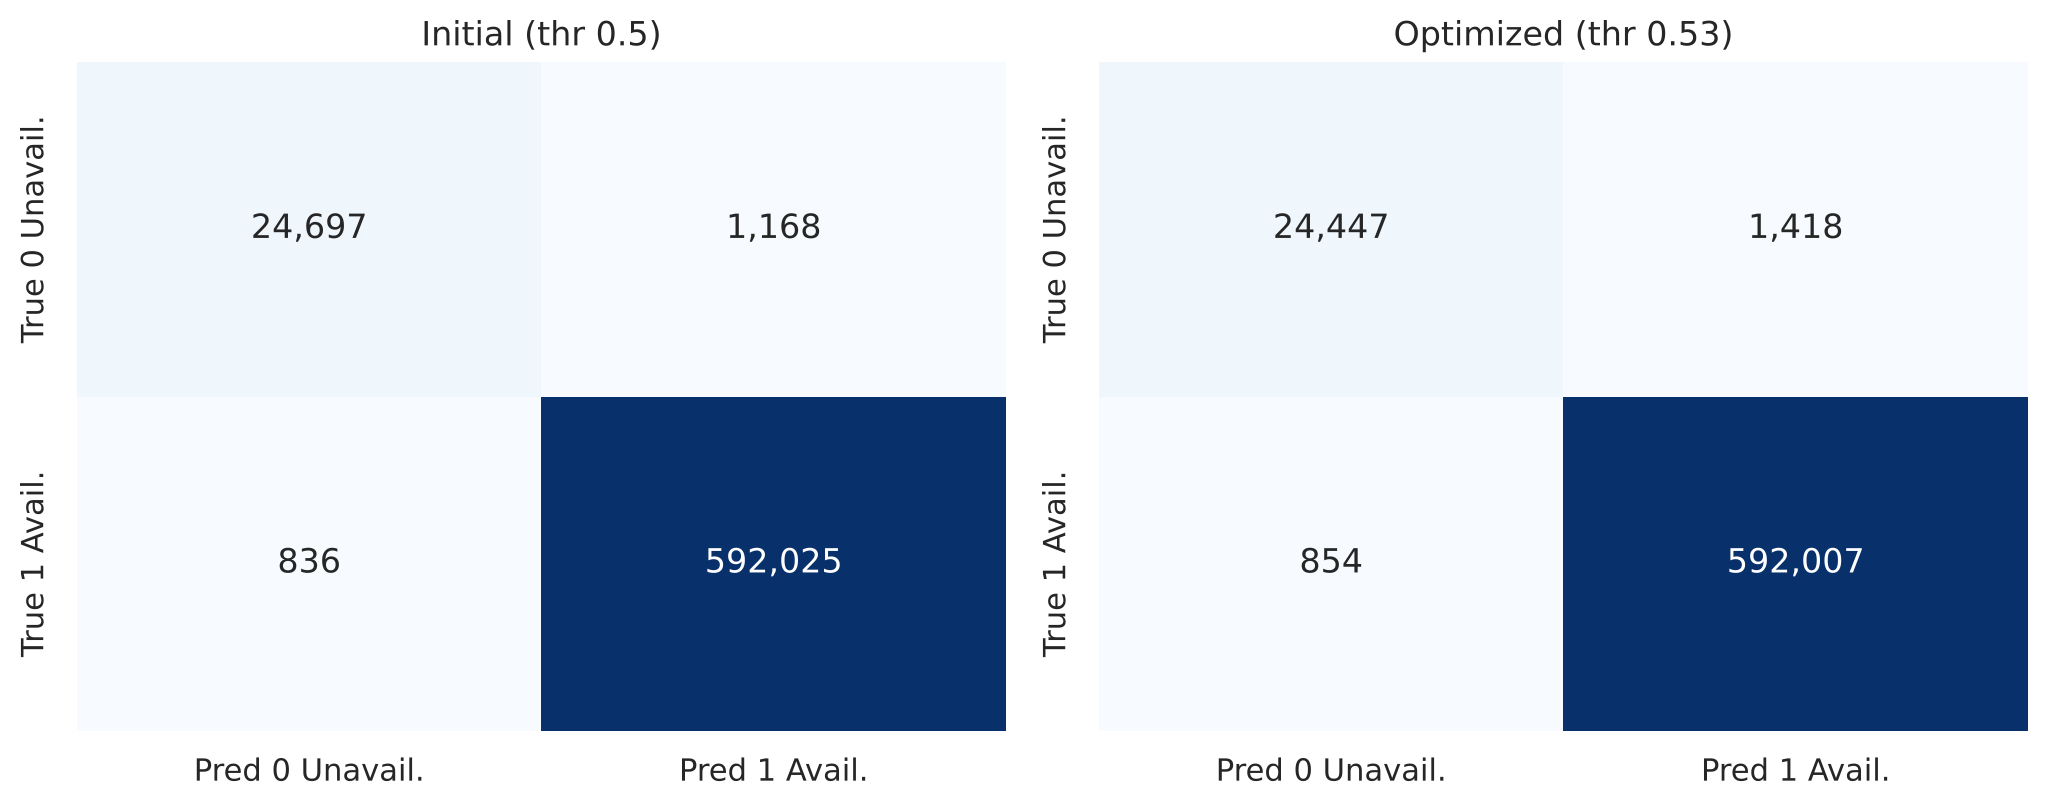

In [27]:
ev.validate_prediction_output(pred_opt, reference=validation)
res_opt = ev.export_evaluation_results(pred_opt, training_station_ids, validation, TABLES)
pred_opt.to_parquet(PRED / "xgboost_optimized_validation_predictions.parquet", index=False)
assert (pred_init[["station_id","time","prediction_horizon"]].values == pred_opt[["station_id","time","prediction_horizon"]].values).all()
display(res_opt["overall"][["model_version"] + show]); display(res_opt["by_station_group"][["evaluation_group"] + show]); display(res_opt["by_horizon"][["prediction_horizon"] + show])
plot_cm([res_init, res_opt], ["Initial (thr 0.5)", f"Optimized (thr {THRESHOLD})"], "xgboost_confusion_matrices_initial_vs_optimized.png")
pd.concat([res_init["overall"], res_opt["overall"]])[["model_version"] + [c for c in res_init["overall"].columns if c.startswith("actual_")]].to_csv(TABLES / "xgboost_confusion_matrices.csv", index=False)

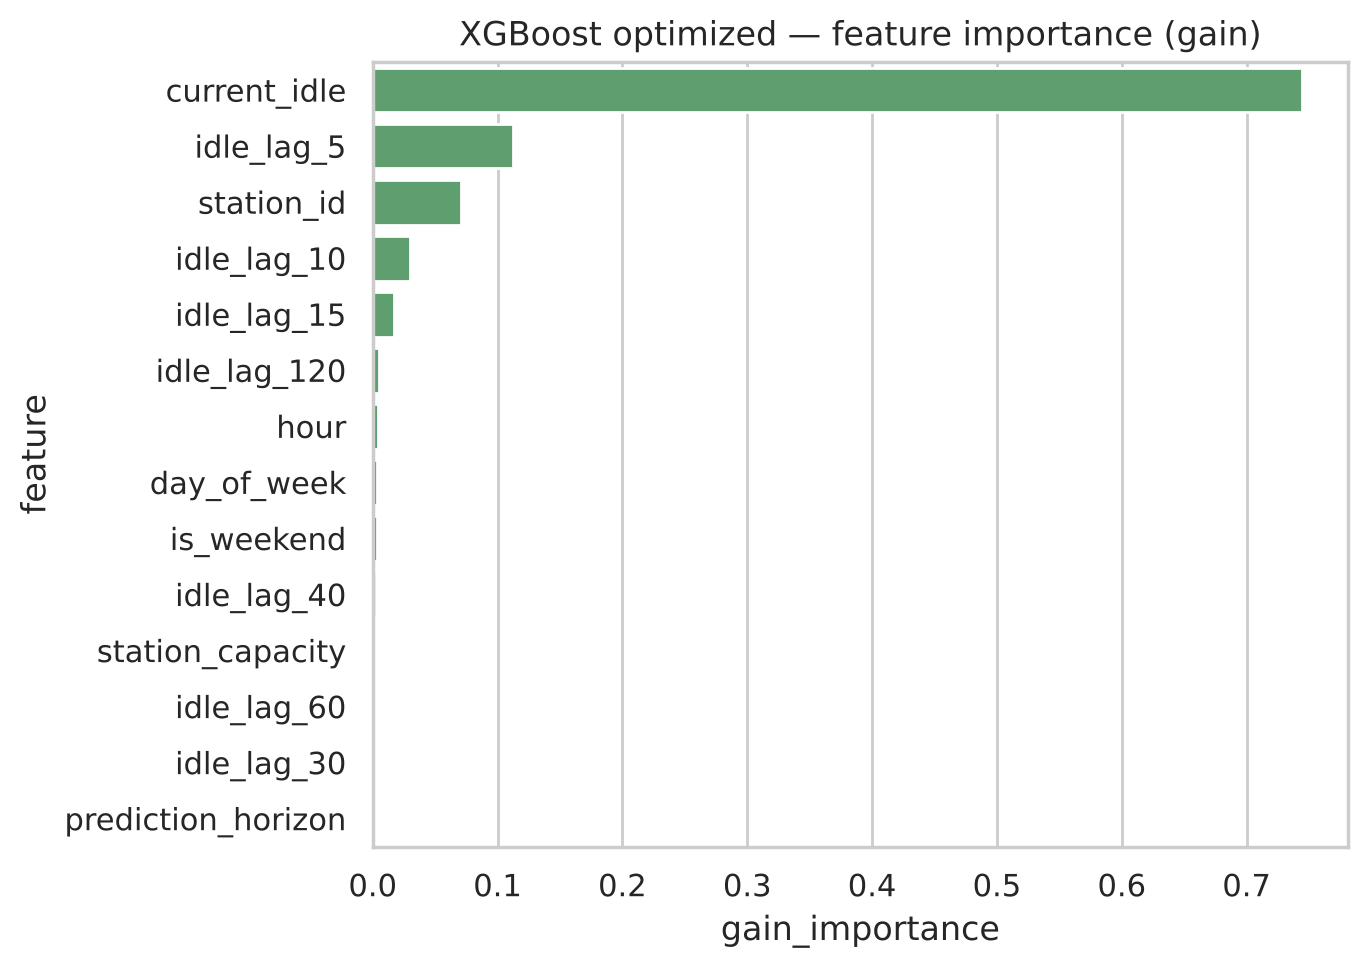

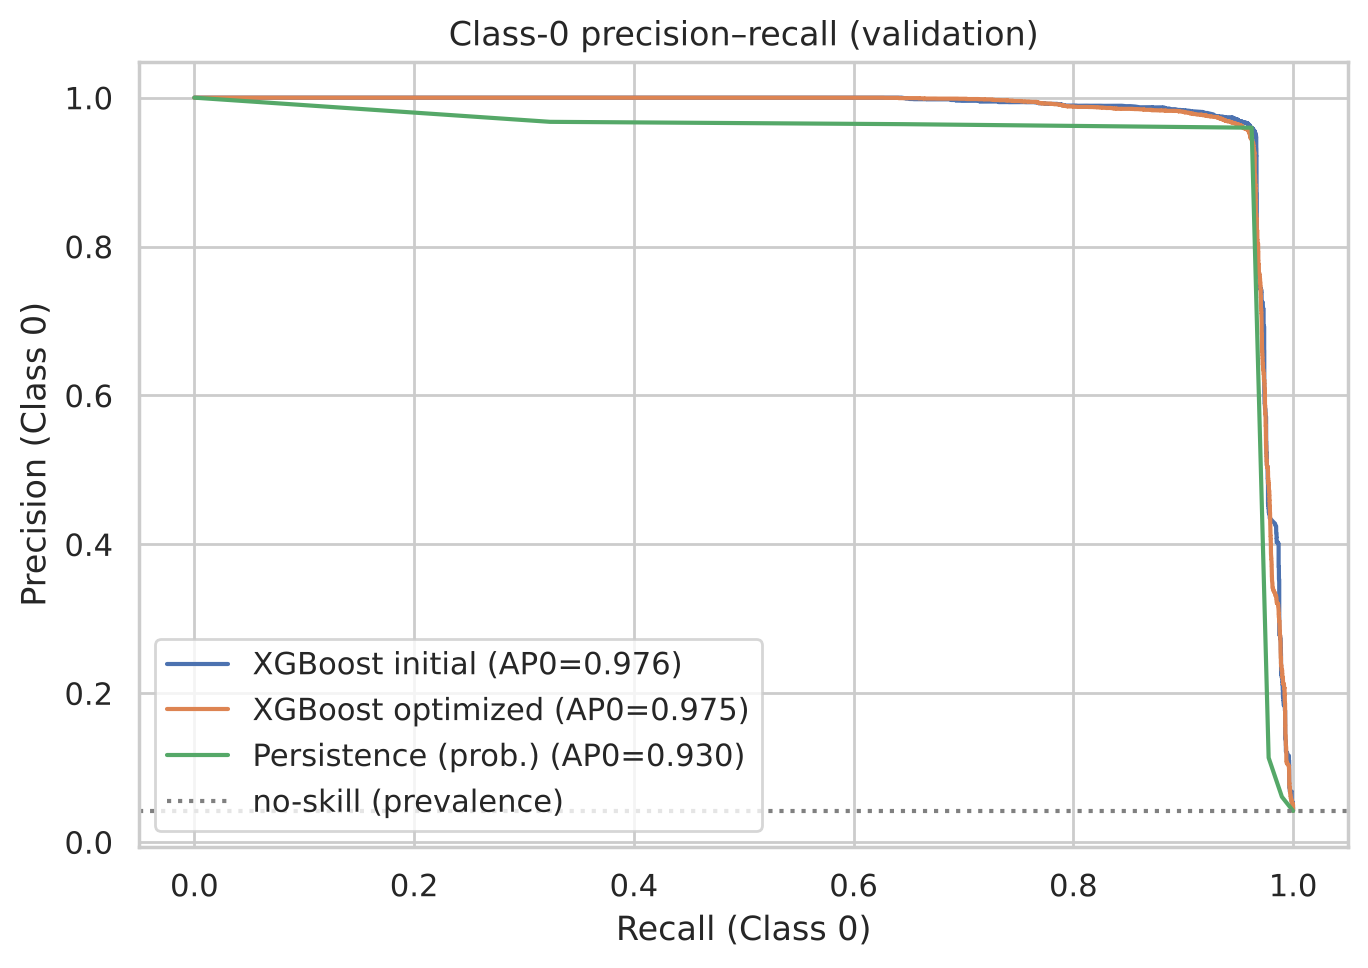

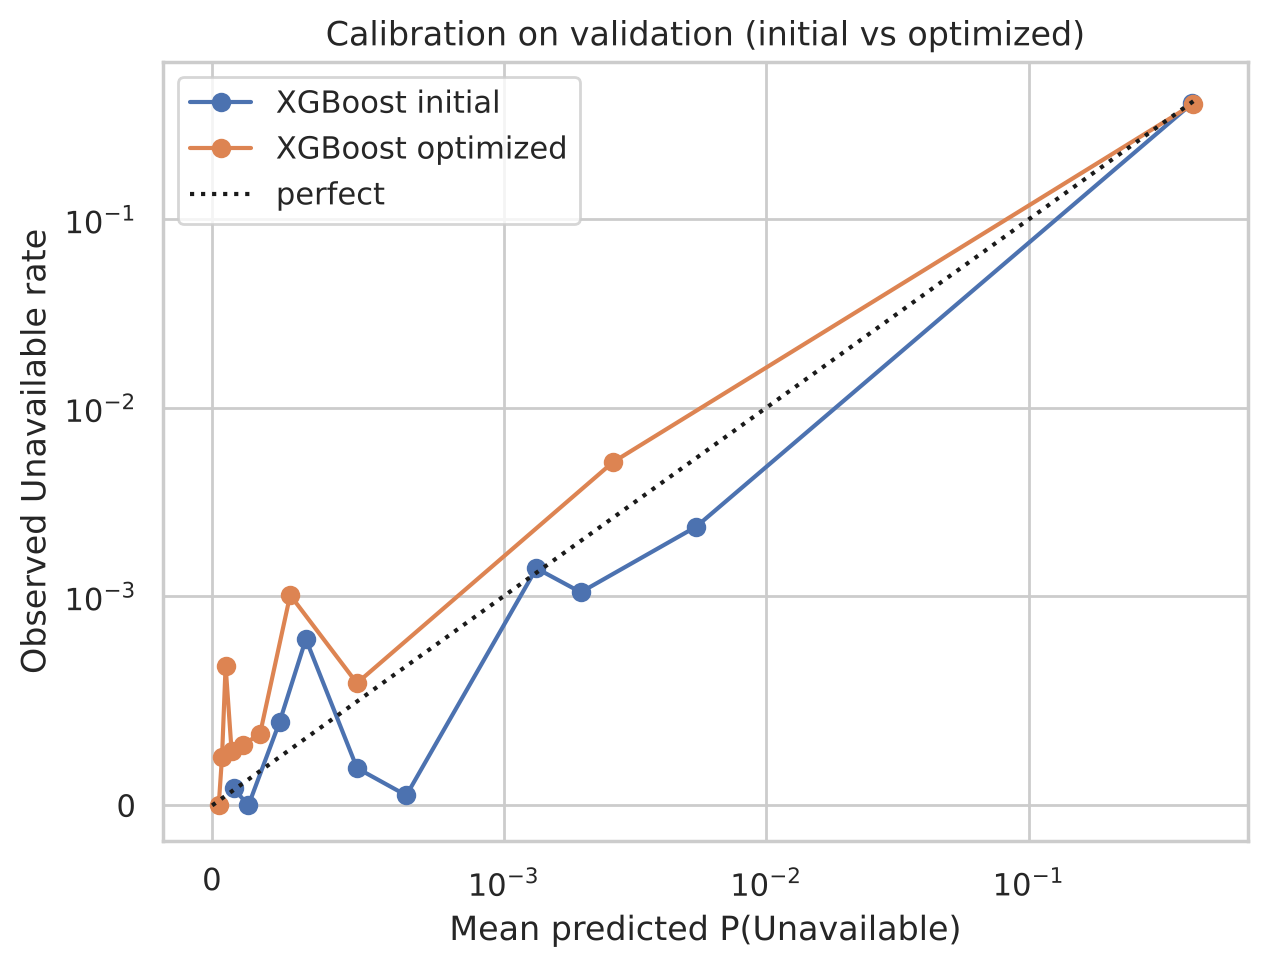

In [28]:
# Feature importance (optimized) and curves
pre_o, mdl_o = pipe_opt.named_steps["preprocess"], pipe_opt.named_steps["model"]
imp_o = pd.Series(mdl_o.feature_importances_, index=pre_o.get_feature_names_out()).groupby(lambda n: "station_id" if n.startswith("station_id_") else n).sum().sort_values(ascending=False)
imp_o_df = imp_o.rename("gain_importance").reset_index().rename(columns={"index": "feature"}); imp_o_df.to_csv(TABLES / "xgboost_optimized_feature_importance.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 5)); sns.barplot(data=imp_o_df, y="feature", x="gain_importance", color="#55A868", ax=ax)
ax.set_title("XGBoost optimized — feature importance (gain)"); fig.tight_layout(); fig.savefig(FIGS / "xgboost_optimized_feature_importance.png", dpi=150); plt.show()
frames = [pred_init, pred_opt] + ([pers] if pers is not None else []); labels = ["XGBoost initial", "XGBoost optimized"] + (["Persistence (prob.)"] if pers is not None else [])
pr_class0(frames, labels, "xgboost_pr_curves_class0.png", "Class-0 precision–recall (validation)")
cal_tab2 = reliability(frames[:2], labels[:2], "xgboost_calibration_validation.png", "Calibration on validation (initial vs optimized)")
cal_tab2.to_csv(TABLES / "xgboost_calibration_curve_validation.csv", index=False)

In [29]:
EA_opt = error_analysis(pred_opt, val_feats, "optimized")
for k, v in EA_opt.items(): v.to_csv(TABLES / f"xgboost_optimized_error_{k}.csv")
display(EA_opt["by_current_state"]); display(EA_opt["by_horizon"]); display(EA_opt["top_stations"].head(5))

,n,unavailable,missed_unavailable,false_alarms
state_now,,,,
available now,592789,975,951,224
unavailable now,25937,24890,467,630


,n,missed_unavailable,false_alarms
prediction_horizon,,,
30,206482,366,245
40,206302,453,263
60,205942,599,346


,n,unavailable,errors,false_alarms,total_errors
station_id,,,,,
1879,6886,771,383,135,518
1763,6886,2352,277,192,469
1888,6886,774,197,249,446
1796,6886,357,101,26,127
1758,6886,3865,34,75,109


## 11. Initial vs optimized vs baselines (same validation rows)

,model,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score,seen_ap0,train_s,infer_s
0,xgboost/initial,0.9968,0.9767,0.9673,0.9548,0.9610,0.9947,0.9763,0.0029,0.9767,25.1976,0.7333
1,xgboost/optimized,0.9963,0.9719,0.9662,0.9452,0.9556,0.9943,0.9750,0.0033,0.9755,24.8227,0.7463
2,persistence/deterministic,0.9967,0.9803,0.9596,0.9623,0.9610,0.9803,0.9250,0.0033,0.9259,NaN,NaN
3,persistence/probability,0.9967,0.9803,0.9596,0.9623,0.9610,0.9821,0.9305,0.0032,0.9313,NaN,NaN
4,majority/global,0.9582,0.5000,NaN,0.0000,0.0000,0.5000,0.0418,0.0401,0.0422,NaN,NaN


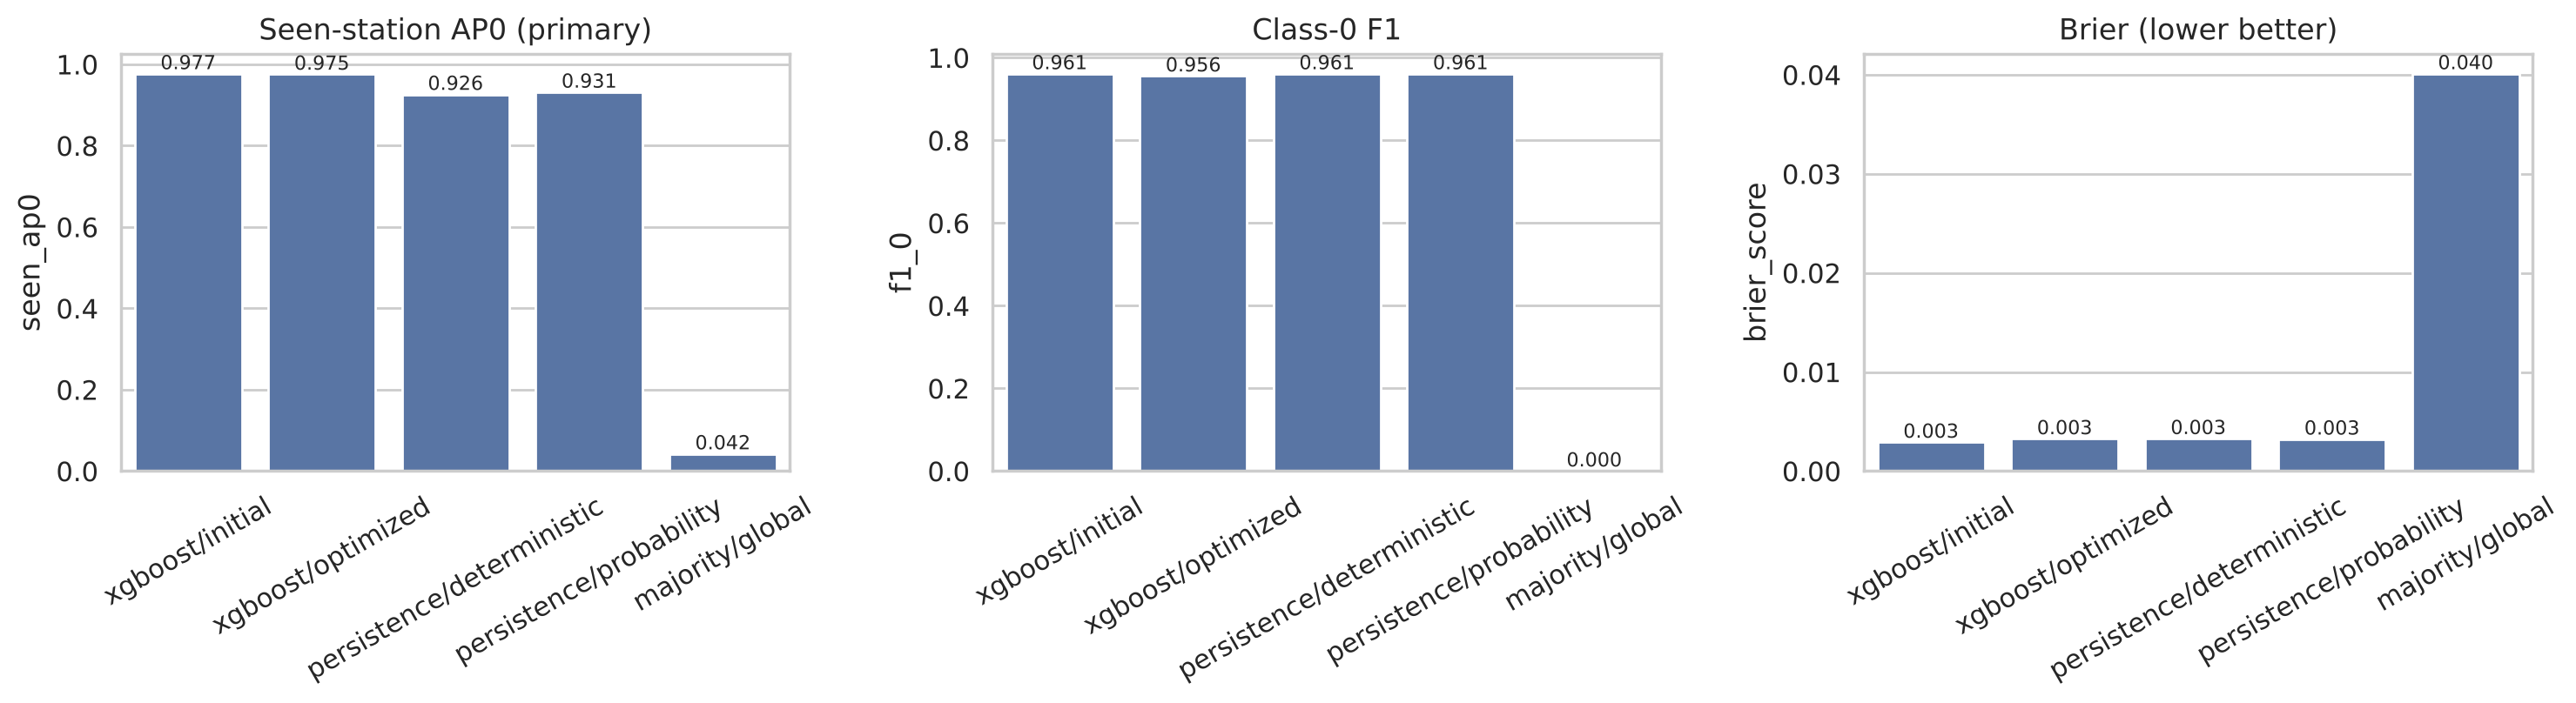

In [30]:
def row(r, lab): o = r["overall"].iloc[0]; return {"model": lab, **{c: o[c] for c in show[1:]}}
def seen_ap(r): return float(r["by_station_group"].query("evaluation_group == 'seen'").ap_0.iloc[0])
cmp = [dict(row(res_init, "xgboost/initial"), seen_ap0=seen_ap(res_init), train_s=TRAIN_SEC_INIT, infer_s=INFER_SEC_INIT),
       dict(row(res_opt, "xgboost/optimized"), seen_ap0=seen_ap(res_opt), train_s=TRAIN_SEC_OPT, infer_s=INFER_SEC_OPT)]
for n, v in (("persistence", "deterministic"), ("persistence", "probability"), ("majority", "global")):
    f = TABLES / f"{n}_{v}_overall.csv"; g = TABLES / f"{n}_{v}_by_station_group.csv"
    if f.exists():
        o = pd.read_csv(f).iloc[0]; s_ = pd.read_csv(g).query("evaluation_group == 'seen'").iloc[0]
        cmp.append({"model": f"{n}/{v}", **{c: o[c] for c in show[1:]}, "seen_ap0": s_.ap_0})
comparison = pd.DataFrame(cmp); comparison.to_csv(TABLES / "xgboost_model_comparison_overall.csv", index=False, na_rep="N/A")
display(comparison)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, m, t in zip(axes, ["seen_ap0", "f1_0", "brier_score"], ["Seen-station AP0 (primary)", "Class-0 F1", "Brier (lower better)"]):
    sns.barplot(data=comparison, x="model", y=m, color="#4C72B0", ax=ax); ax.set_title(t); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30)
    for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "xgboost_vs_baselines.png", dpi=150); plt.show()

## 12. Save / reload verification

In [31]:
sample = validation.sample(60_000, random_state=SEED)
for name, art in (("initial", art_init), ("optimized", art_opt)):
    re = xm.load_xgboost_artifact(MODELS / f"xgboost_{name}.joblib")
    a, b_ = xm.predict_xgboost(art, sample), xm.predict_xgboost(re, sample)
    assert np.allclose(a.y_prob, b_.y_prob, atol=1e-12) and (a.y_pred == b_.y_pred).all()
    print(name, "reload OK | threshold", re["threshold"], "| calibrator", None if re.get("calibrator") is None else re["calibrator"]["method"])
bst = xm.XGBClassifier(); bst.load_model(str(MODELS / "xgboost_optimized_booster.json"))
Xs = pipe_opt.named_steps["preprocess"].transform(sample[SELECTED_COLS])
assert np.allclose(bst.predict_proba(Xs)[:, 1], xm.raw_probability(pipe_opt, sample[SELECTED_COLS]), atol=1e-6); print("native booster JSON reload OK")
# unseen station: encoder must not fail and must give a valid probability
u = validation[validation.station_id == 1948].head(5); print("unseen station 1948 probabilities:", np.round(xm.predict_xgboost(art_opt, u).y_prob.to_numpy(), 4))

initial reload OK | threshold 0.5 | calibrator None
optimized reload OK | threshold 0.53 | calibrator None


native booster JSON reload OK
unseen station 1948 probabilities: [1. 1. 1. 1. 1.]


## 13. Findings & Conclusion

In [32]:
oi, oo = res_init["overall"].iloc[0], res_opt["overall"].iloc[0]
si, so = seen_ap(res_init), seen_ap(res_opt)
pers_prob = comparison.query("model == 'persistence/probability'"); pers_det = comparison.query("model == 'persistence/deterministic'")
lines = [
 f"**Primary metric (seen-station validation AP0):** initial {si:.4f} → optimized {so:.4f} (Δ {so-si:+.4f}).",
 f"**Overall validation:** Class-0 F1 {oi.f1_0:.4f} → {oo.f1_0:.4f}; Balanced Accuracy {oi.balanced_accuracy:.4f} → {oo.balanced_accuracy:.4f}; Brier {oi.brier_score:.5f} → {oo.brier_score:.5f}; ROC-AUC {oi.roc_auc:.4f} → {oo.roc_auc:.4f}.",
 f"**Frozen configuration:** {len(SELECTED_COLS)} features ({SELECTED_SET_NAME}), learning_rate={SEL['learning_rate']}, max_depth={SEL['max_depth']}, n_estimators={SEL['n_estimators']}, min_child_weight={SEL['min_child_weight']}, subsample={SEL['subsample']}, colsample_bytree={SEL['colsample_bytree']}, reg_alpha={SEL['reg_alpha']}, reg_lambda={SEL['reg_lambda']}, class-0 sample weight={BEST_W0}, calibration={CAL_METHOD}, threshold={THRESHOLD}.",
]
if len(pers_prob):
    pp_ap = float(pers_prob.seen_ap0.iloc[0]); pd_ap = float(pers_det.seen_ap0.iloc[0])
    verdict = "outperforms" if so > pp_ap else "does NOT outperform"
    lines.append(f"**Versus baselines:** optimized XGBoost {verdict} the probability-persistence baseline on seen-station AP0 ({so:.4f} vs {pp_ap:.4f}; deterministic persistence {pd_ap:.4f}). Majority is the no-skill floor (AP0 ≈ unavailable prevalence).")
unseen_o = res_opt["by_station_group"].query("evaluation_group == 'unseen'").iloc[0]
lines.append(f"**Unseen station 1948:** {int(unseen_o.n_observations):,} rows with only {int(unseen_o.actual_0_predicted_0 + unseen_o.actual_0_predicted_1)} Class-0 observations, so its Class-0 metrics are very noisy and must not be over-interpreted; seen-station AP0 is the primary metric.")
lines.append("**Method notes:** hyperparameters were selected on Dec 24–29 only; the estimator was refit on Dec 1–29; calibration used Dec 30–Jan 2 without refitting; the threshold used Jan 3–5; validation was used only for reporting; test data was never loaded. `scale_pos_weight` was not used because it targets the Available class; class-0 sample weights were evaluated instead.")
display(Markdown("\n\n".join("- " + l for l in lines)))

- **Primary metric (seen-station validation AP0):** initial 0.9767 → optimized 0.9755 (Δ -0.0012).

- **Overall validation:** Class-0 F1 0.9610 → 0.9556; Balanced Accuracy 0.9767 → 0.9719; Brier 0.00290 → 0.00325; ROC-AUC 0.9947 → 0.9943.

- **Frozen configuration:** 14 features (no_redundant (-current_busy,-occupancy_rate)), learning_rate=0.1, max_depth=8, n_estimators=100, min_child_weight=5, subsample=1.0, colsample_bytree=0.8, reg_alpha=1.0, reg_lambda=1.0, class-0 sample weight=1.0, calibration=none, threshold=0.53.

- **Versus baselines:** optimized XGBoost outperforms the probability-persistence baseline on seen-station AP0 (0.9755 vs 0.9313; deterministic persistence 0.9259). Majority is the no-skill floor (AP0 ≈ unavailable prevalence).

- **Unseen station 1948:** 5,872 rows with only 12 Class-0 observations, so its Class-0 metrics are very noisy and must not be over-interpreted; seen-station AP0 is the primary metric.

- **Method notes:** hyperparameters were selected on Dec 24–29 only; the estimator was refit on Dec 1–29; calibration used Dec 30–Jan 2 without refitting; the threshold used Jan 3–5; validation was used only for reporting; test data was never loaded. `scale_pos_weight` was not used because it targets the Available class; class-0 sample weights were evaluated instead.

## 14. `model_config.json`, `training_metadata.json` and artifact manifest

In [33]:
config = {"model_name": "xgboost", "versions": ["initial", "optimized"], "seed": SEED, "target": "1=Available, 0=Unavailable", "y_prob": "P(Available=1)",
 "feature_columns": F, "encoding": "OneHotEncoder(handle_unknown='ignore') on station_id; numerics passthrough",
 "initial": {"params": INITIAL_PARAMS, "threshold": 0.5, "fit_period": "2022-12-01..2022-12-23"},
 "optimized": {"params": SEL, "class0_sample_weight": BEST_W0, "features": SELECTED_COLS, "feature_set": SELECTED_SET_NAME, "calibration_method": CAL_METHOD,
               "threshold": THRESHOLD, "threshold_selection": "max Class-0 F1 on Jan 3-5 (class 0 predicted when y_prob < threshold)", "fit_period": "2022-12-01..2022-12-29",
               "calibration_period": "2022-12-30..2023-01-02", "threshold_period": "2023-01-03..2023-01-05"},
 "scale_pos_weight_used": False}
meta = {"environment": ENV, "dataset_rows": {"train": len(train), "validation": len(validation), "model_fit": len(mf), "tuning": len(splits["tuning"]),
        "calibration": len(splits["calibration"]), "threshold": len(splits["threshold"]), "refit_dec1_29": len(fit_tuning), "development_sample": len(dev)},
 "training_seconds": {"initial": round(TRAIN_SEC_INIT, 2), "optimized_refit": round(TRAIN_SEC_OPT, 2)},
 "inference_seconds_validation": {"initial": round(INFER_SEC_INIT, 2), "optimized": round(INFER_SEC_OPT, 2)},
 "unseen_validation_stations": unseen, "test_data_used": False, "tuning_runs": len(tune_df)}
manifest = {"artifacts_not_in_git (share via team artifact folder)": {p.name: {"bytes": p.stat().st_size} for p in sorted(list(MODELS.glob("xgboost_*")) + list(PRED.glob("xgboost_*")) + list(PRED.glob("persistence_*")) + list(PRED.glob("majority_*")))}}
for n, o in (("xgboost_model_config.json", config), ("xgboost_training_metadata.json", meta), ("xgboost_artifact_manifest.json", manifest)):
    (TABLES / n).write_text(json.dumps(o, indent=2, default=str))
print(json.dumps(meta, indent=2, default=str)); print(json.dumps(manifest, indent=2))

{
  "environment": {
    "python": "3.13.18",
    "os": "Linux-6.18.44-fc-v880-x86_64-with-glibc2.39",
    "cpu_count": 2,
    "ram_gb": 7.8,
    "numpy": "2.5.3",
    "pandas": "3.0.5",
    "sklearn": "1.9.1",
    "n_jobs": 2,
    "seed": 42,
    "git_commit": null,
    "xgboost": "3.4.1"
  },
  "dataset_rows": {
    "train": 2798569,
    "validation": 618726,
    "model_fit": 1790062,
    "tuning": 466897,
    "calibration": 306216,
    "threshold": 228374,
    "refit_dec1_29": 2259325,
    "development_sample": 447567
  },
  "training_seconds": {
    "initial": 25.2,
    "optimized_refit": 24.82
  },
  "inference_seconds_validation": {
    "initial": 0.73,
    "optimized": 0.75
  },
  "unseen_validation_stations": [
    1948
  ],
  "test_data_used": false,
  "tuning_runs": 35
}
{
  "artifacts_not_in_git (share via team artifact folder)": {
    "xgboost_initial.joblib": {
      "bytes": 320419
    },
    "xgboost_initial_preprocessor.joblib": {
      "bytes": 3149
    },
    "xgboost